# Förutsägelse av pallplatser i Formel 1

**Författare:** Felixalfred

I det här projektet undersöker jag om man kan förutsäga vilka förare som tar pallplats (topp 3) i ett Formel 1-lopp, utifrån information som är känd **före** loppet, och vilka faktorer som spelar störst roll.

**Data:** [Formula 1 World Championship (1950-2026)](https://www.kaggle.com/datasets/atharvranjan/formula-1-world-championship-1950-present) från Kaggle.

### Så kör du notebooken
1. Installera paketen: `pip install -r requirements.txt`
2. Öppna notebooken och välj *Run All*. Cellerna är gjorda för att köras uppifrån och ned.

### Innehåll
1. Problem och varför maskininlärning behövs
2. Data och urval
3. Utforskande analys (EDA)
4. Statistiska tester
5. Preprocessing och features
6. Modeller och jämförelse
7. Tolkning av modellen
8. Extra experiment
9. Så fungerar modellen, förklarat utan jargong
10. Slutsats och begränsningar

## Ordlista: Formel 1-begrepp

För den som inte följer Formel 1 förklaras här de begrepp som används i notebooken.

| Begrepp | Förklaring |
|---|---|
| **Lopp (Grand Prix)** | En tävling som körs en gång per tävlingshelg, oftast på söndagen. |
| **Säsong** | Ett år med lopp. I datan har säsongerna mellan 15 och 24 lopp. |
| **Förare** | Den som kör bilen. Varje stall har normalt två förare. |
| **Stall** | Laget som bygger och driver bilarna (t.ex. Ferrari, Mercedes). Stallen tävlar också mot varandra i ett eget mästerskap. |
| **Kval (kvalificering)** | Sessionen före loppet där förarna kör ett snabbt varv var. Resultatet avgör startordningen i loppet. |
| **Grid / startposition** | Startordningen i loppet. Grid 1 står längst fram, grid 2 bredvid osv. |
| **Pole position** | Första startplatsen, som den förare får som kört snabbast i kvalet. Föraren kallas *polesittare*. I den här analysen betyder pole "startade från grid 1", vilket i enstaka fall kan skilja sig från den som körde snabbast, eftersom förare ibland får nedflyttning på griden. |
| **Depåstart** | Start från depån i stället för från griden. I datan visas det oftast som grid 0. |
| **Pallplats (podium)** | Att sluta på plats 1, 2 eller 3 i loppet. De tre första står på prispallen. Det är det jag försöker förutsäga. |
| **Målposition** | Placeringen i mål. Saknas för förare som inte blev klassificerade. |
| **Att bryta loppet (DNF)** | Att inte ta sig i mål, till exempel på grund av olycka eller motorfel. Sådana förare saknar målposition i datan. |
| **Hybrid-eran** | Perioden från 2014, då bilarna började använda turboladdade hybridmotorer. Min analys börjar där. |
| **Poäng** | Förarna och stallen får poäng efter placering i loppet. |

## 1. Problem och varför maskininlärning behövs

**Frågeställning:** Kan man förutsäga om en förare tar pallplats (plats 1-3) i ett lopp, utifrån sådant som är känt före start, till exempel startposition, kvalresultat samt förarens och stallets form? Vilka faktorer väger tyngst?

**Typ av problem:** Binär klassificering. Målvariabeln är *pallplats* (ja/nej). Klasserna är obalanserade, eftersom bara tre av ungefär tjugo förare hamnar på pallen i varje lopp (ca 15 %).

**Varför räcker det inte med en enkel regel?** En vanlig tumregel är "den som står på pole vinner". Men hur mycket startpositionen betyder varierar mellan banor (det är svårt att köra om på Monaco), mellan stall (en snabb bil kan köra upp från mitten av fältet) och mellan år (regler och bilar kan förändras). Flera faktorer samverkar dessutom. Maskininlärning kan väga ihop många signaler samtidigt och lära sig dessa samband från historiska lopp. Jag jämför därför modellerna mot just tumregeln, för att visa om maskininlärning faktiskt tillför något.

## 2. Data och urval

Datasetet består av flera tabeller (CSV-filer) som hänger ihop via id-kolumner, till exempel `raceId` och `driverId`. Jag använder dessa:

| Tabell | Innehåll |
|---|---|
| `results` | Resultat per förare och lopp: startposition (`grid`), målposition, poäng, status |
| `races` | Ett lopp per rad: säsong, rundenummer, bana, datum |
| `qualifying` | Kvalresultat per förare och lopp, inklusive tider i Q1, Q2 och Q3 |
| `drivers` | Information om förarna |
| `constructors` | Information om stallen |
| `circuits` | Information om banorna, bland annat koordinater |
| `status` | Förklaring av hur varje förare avslutade loppet (t.ex. i mål, olycka, motorfel) |

Datasetet innehåller också tabellerna `lap_times` och `pit_stops`, men de behövs inte för den här frågeställningen och används därför inte.

### 2.1 Importer och sökväg till datan

Först importerar jag de bibliotek jag behöver:
- `pandas` för att läsa in och hantera tabeller
- `Path` från standardbiblioteket för att hantera filsökvägar på ett sätt som fungerar på både Windows, Mac och Linux

Notebooken ligger i mappen `notebooks/` och datan i `data_raw/`. Därför går sökvägen först upp en nivå (`..`) och sedan in i `data_raw`.

In [1]:
import pandas as pd
from pathlib import Path

# Mappen med rådatan, sett från notebookens plats
DATA = Path("../data_raw")

### 2.2 Funktion för att läsa in en tabell

Jag skriver en liten funktion så att jag slipper upprepa samma rad för varje tabell.

Viktigt här är `na_values="\\N"`. I datasetet står tecknen `\N` där ett värde saknas. Om jag inte berättar det för pandas tolkas `\N` som vanlig text, och då blir hela kolumner (t.ex. `position`) textkolumner i stället för tal. Med inställningen omvandlas `\N` till riktiga saknade värden (`NaN`), som jag kan hantera på ett kontrollerat sätt.

In [2]:
def load(name):
    """Läser in en CSV-fil från data_raw och returnerar den som en pandas-tabell (DataFrame)."""
    return pd.read_csv(DATA / f"{name}.csv", na_values="\\N")

### 2.3 Läs in tabellerna

Varje tabell sparas i en egen variabel med samma namn som filen.

In [3]:
results       = load("results")
races         = load("races")
qualifying    = load("qualifying")
drivers       = load("drivers")
constructors  = load("constructors")
circuits      = load("circuits")
status        = load("status")

### 2.4 Kontrollera storleken

Det första jag gör efter inläsning är att kontrollera att tabellerna har rimlig storlek. `shape` visar *(antal rader, antal kolumner)*. Det är en enkel kontroll av att inläsningen gått rätt till och att inga filer är tomma eller trasiga.

In [4]:
tabeller = {
    "results": results,
    "races": races,
    "qualifying": qualifying,
    "drivers": drivers,
    "constructors": constructors,
    "circuits": circuits,
    "status": status,
}

for namn, tabell in tabeller.items():
    print(f"{namn:<13} {tabell.shape[0]:>6} rader, {tabell.shape[1]:>2} kolumner")

results        27568 rader, 18 kolumner
races           1164 rader, 18 kolumner
qualifying     11298 rader,  9 kolumner
drivers          879 rader,  9 kolumner
constructors     214 rader,  5 kolumner
circuits          78 rader,  9 kolumner
status           141 rader,  2 kolumner


### 2.5 Titta på de första raderna

`head()` visar de fem första raderna. Det ger en känsla för hur datan ser ut. Här ser jag bland annat att varje rad i `results` är en förare i ett lopp, och att tabellen hänvisar till andra tabeller via id-kolumner (`raceId`, `driverId`, `constructorId`).

In [5]:
results.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


### 2.6 Datatyper och saknade värden

Jag kontrollerar att kolumnerna har rätt datatyp (tal ska vara tal) och hur många värden som saknas. `dtypes` visar datatypen per kolumn och `isna().sum()` räknar saknade värden.

Saknade värden är inte alltid fel. En förare som bröt loppet har till exempel ingen målposition (`position`). Det betyder att tabellen innehåller information i sig, och det tar jag hänsyn till när jag bygger målvariabeln.

In [6]:
results.dtypes

resultId             int64
raceId               int64
driverId             int64
constructorId        int64
number             float64
grid                 int64
position           float64
positionText           str
positionOrder        int64
points             float64
laps                 int64
time                   str
milliseconds       float64
fastestLap         float64
rank               float64
fastestLapTime         str
fastestLapSpeed    float64
statusId             int64
dtype: object

In [7]:
results.isna().sum()

resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           11074
positionText           0
positionOrder          0
points                 0
laps                   0
time               19212
milliseconds       19200
fastestLap         18542
rank               18284
fastestLapTime     18542
fastestLapSpeed    19316
statusId               0
dtype: int64

### 2.7 Vilka säsonger finns i datan, och varför väljer jag 2014-2026?

Datasetet täcker 1950 till 2026, men jag avgränsar analysen till **2014-2026**. Skälen är:

- **Jämförbara regler och bilar.** Säsongen 2014 infördes hybridtekniken med turboladdade V6-motorer, och sedan dess är bilarna och förutsättningarna rimligt jämförbara. Ett lopp från 1970-talet och ett från 2020-talet skiljer sig så mycket i teknik, säkerhet och tillförlitlighet att en modell som lär sig av båda lätt blir svårtolkad. Det är till exempel mycket vanligare att bilar går sönder i äldre lopp.
- **Mer komplett data.** Tabellen `pit_stops` finns bara från 2011, och det gäller flera andra tabeller också. Att börja 2014 ger fullständiga uppgifter för alla de tabeller jag vill kunna använda.
- **Tillräckligt många observationer.** Perioden ger 13 säsonger och drygt 5 400 rader i `results` (en per förare och lopp), vilket räcker för att träna och jämföra flera modeller.
- **Aktuell relevans.** Jag vill kunna testa modellen på de senaste loppen, vilket ligger närmast hur sporten fungerar nu.

**Begränsningar:** Perioden innehåller också regelförändringar, bland annat 2022 (nya aerodynamiska regler) och 2026 (nya tekniska regler, och två nya stall, Audi och Cadillac). Säsongen 2026 är dessutom inte komplett i datan. Jag hanterar det genom att dela upp datan i tid, så att modellen tränas på äldre säsonger och testas på de senaste, och jag tar upp effekten i diskussionen.

Först kollar jag vilka år som finns och hur många lopp varje säsong har.

In [8]:
# Första säsongen som tas med i analysen (hybrid-eran börjar 2014)
FIRST_SEASON = 2014

print("Första säsong i datan:", races["year"].min())
print("Senaste säsong i datan:", races["year"].max())

# Antal lopp per säsong i den period jag analyserar
races[races["year"] >= FIRST_SEASON].groupby("year").size()

Första säsong i datan: 1950
Senaste säsong i datan: 2026


year
2014    19
2015    19
2016    21
2017    20
2018    21
2019    21
2020    17
2021    22
2022    22
2023    22
2024    24
2025    24
2026    15
dtype: int64

### 2.8 Slå ihop tabellerna till en analystabell

Datan ligger i flera tabeller, men för analysen vill jag ha **en tabell med en rad per förare och lopp**. Jag utgår från `results` och lägger till information om loppet (säsong, bana, namn), föraren och stallet. Tabellerna kopplas ihop via id-kolumnerna (`raceId`, `driverId`, `constructorId`) med `merge`.

Två detaljer som gör sammanslagningen säker:
- `how="left"` behåller alla rader från `results`, även om en matchning skulle saknas.
- `validate="many_to_one"` kontrollerar att varje resultatrad matchar **exakt en** rad i den andra tabellen. Om id-kolumnerna skulle innehålla dubbletter hade pandas gett ett felmeddelande i stället för att tyst skapa extra rader.

Jag kontrollerar också att antalet rader är oförändrat efter sammanslagningen. Kolumnerna `points` och `statusId` tar jag med för den utforskande analysen, men de beskriver resultatet av loppet och är därför **inte** tillåtna som features i modellen. Det skulle vara dataläckage.

In [9]:
# Välj ut de kolumner jag behöver och döp om de som har samma namn i olika tabeller
races_small = races[["raceId", "year", "round", "circuitId", "name", "date"]].rename(columns={"name": "race_name"})
drivers_small = drivers[["driverId", "forename", "surname"]]
constructors_small = constructors[["constructorId", "name"]].rename(columns={"name": "constructor_name"})

# Slå ihop: varje resultatrad får info om lopp, förare och stall
df = (
    results
    .merge(races_small, on="raceId", how="left", validate="many_to_one")
    .merge(drivers_small, on="driverId", how="left", validate="many_to_one")
    .merge(constructors_small, on="constructorId", how="left", validate="many_to_one")
)

# Förarens fulla namn i en kolumn
df["driver"] = df["forename"] + " " + df["surname"]

# Behåll bara de kolumner jag behöver
df = df[["raceId", "year", "round", "race_name", "date", "circuitId", "driverId", "driver",
         "constructorId", "constructor_name", "grid", "position", "positionOrder", "points", "statusId"]]

# Kontroll: samma antal rader som i results?
print("Samma antal rader som results:", len(df) == len(results), "-", len(df), "rader")

Samma antal rader som results: True - 27568 rader


### 2.9 Avgränsa till den valda perioden

Nu filtrerar jag bort säsongerna före `FIRST_SEASON` (2014), enligt motiveringen i avsnitt 2.7. `.copy()` gör en egen kopia av den filtrerade tabellen, så att jag senare kan lägga till kolumner utan varningar från pandas.

In [10]:
df = df[df["year"] >= FIRST_SEASON].copy()

print("Rader:", len(df))
print("Säsonger:", df["year"].min(), "-", df["year"].max())
print("Antal lopp:", df["raceId"].nunique())

Rader: 5435
Säsonger: 2014 - 2026
Antal lopp: 267


### 2.10 Skapa målvariabeln: pallplats

Det jag vill förutsäga är om en förare **tar pallplats**, det vill säga slutar på plats 1, 2 eller 3. Jag skapar därför kolumnen `podium` med värdet 1 om `position` är 3 eller lägre, och annars 0.

Förare som inte kom i mål saknar värde i `position` (`NaN`). I en jämförelse som `NaN <= 3` blir resultatet falskt, så de får automatiskt `podium = 0`. Det är rimligt, eftersom en förare som bröt loppet inte kan ha tagit pallplats.

Som kontroll räknar jag antalet pallplatser per lopp. Det ska vara exakt tre i varje lopp. Om något lopp avviker tyder det på ett fel i datan eller i min definition.

In [11]:
# 1 = pallplats (plats 1-3), 0 = ingen pallplats (inklusive de som bröt loppet)
df["podium"] = (df["position"] <= 3).astype(int)

# Kontroll: antal pallplatser per lopp ska vara exakt 3
df.groupby("raceId")["podium"].sum().value_counts()

podium
3    267
Name: count, dtype: int64

### 2.11 Hur ser fördelningen av målvariabeln ut?

Innan jag modellerar vill jag veta hur vanligt det är med pallplats. Det avgör både hur jag ska utvärdera modellerna och vad en enkel gissning skulle ge. Eftersom bara tre av ungefär tjugo förare hamnar på pallen i varje lopp är klasserna **obalanserade**: en modell som alltid gissar "ingen pallplats" skulle ha ungefär 85 % rätt utan att ha lärt sig något. Därför räcker det inte att titta på accuracy (andelen rätt), utan jag använder mått som tar hänsyn till obalansen (t.ex. ROC-AUC, precision och recall).

Jag kollar också hur många förare som startade från grid-position 0. Det betyder oftast start från depån, och de behöver hanteras särskilt i preprocessingen senare.

In [12]:
print("Antal per klass:")
print(df["podium"].value_counts())
print()
print(f"Andel pallplatser: {df['podium'].mean():.1%}")
print()
print("Antal starter med grid = 0:", (df["grid"] == 0).sum())

Antal per klass:
podium
0    4634
1     801
Name: count, dtype: int64

Andel pallplatser: 14.7%

Antal starter med grid = 0: 79


## 3. Utforskande analys (EDA)

Innan jag bygger några modeller undersöker jag datan för att förstå vad den innehåller och vilka samband som finns. Jag ställer fyra frågor som är kopplade till frågeställningen:

1. Hur mycket betyder startpositionen för chansen till pallplats?
2. Hur ofta vinner den som står på pole, och är det stabilt över åren?
3. Hur ofta når förare inte målet, och har det ändrats?
4. Hur har stallens styrka förändrats över tid?

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ljus bakgrund med rutnät för alla diagram
sns.set_theme(style="whitegrid")

### 3.1 Startposition och chans till pallplats

Först undersöker jag sambandet mellan startposition (`grid`) och pallplats. Jag beräknar andelen förare som tog pallplats för varje startposition. Positionerna 1-20 tas med, eftersom grid 0 (start från depån) och grid 21-22 (finns bara vissa säsonger) har för få observationer för att vara meningsfulla.

grid
1    80.9
2    71.7
3    54.3
4    35.6
5    17.2
Name: podium, dtype: float64


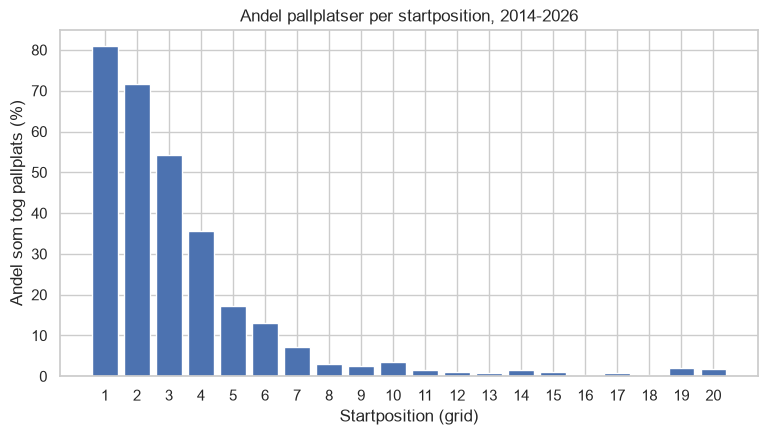

In [14]:
# Andel pallplatser (%) per startposition
podium_by_grid = (
    df[df["grid"].between(1, 20)]
    .groupby("grid")["podium"]
    .mean() * 100
)
print(podium_by_grid.head(5).round(1))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(podium_by_grid.index, podium_by_grid.values, color="#4C72B0")
ax.set_xlabel("Startposition (grid)")
ax.set_ylabel("Andel som tog pallplats (%)")
ax.set_title("Andel pallplatser per startposition, 2014-2026")
ax.set_xticks(range(1, 21))
plt.show()

**Tolkning:** Startpositionen har ett mycket starkt samband med pallplats. Från pole tog 80,9 % pallplats, från plats 2 71,7 %, från plats 3 54,3 % och från plats 4 35,6 %. Efter plats 7 är andelen under 10 %, och från plats 8 och bakåt nästan noll. Sambandet är alltså starkt men inte deterministiskt: nästan var femte polesittare (19 %) tog **inte** pallplats. Det visar att startposition är en viktig feature, men att den inte räcker själv.

### 3.2 Hur ofta vinner den som startar från pole?

Tumregeln "den som står på pole vinner" är den enklaste prognosen jag kan jämföra mot. Här undersöker jag hur bra den är, och om den fungerar lika bra varje säsong. Med pole menar jag här grid-position 1. Den kan skilja sig från den som faktiskt tog bästa kvaltid, eftersom förare ibland får nedflyttning på startgriden.

Antal polepositioner: 267
Andel som vann: 54.3%
Andel som tog pallplats: 80.9%


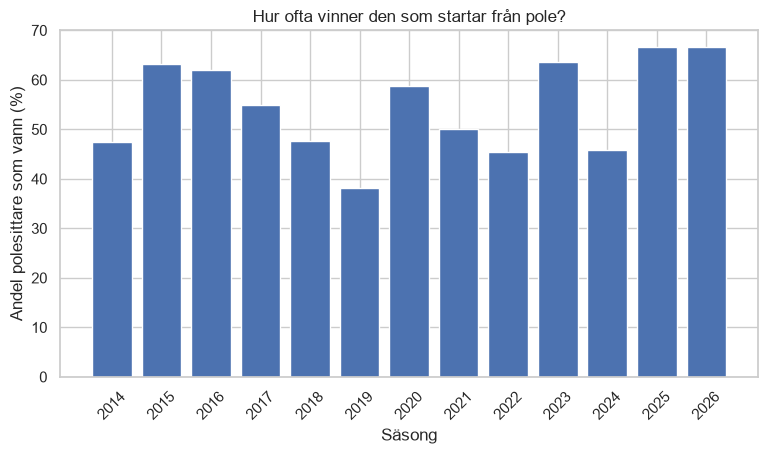

In [15]:
# Polesittare = förare som startade från grid-position 1
pole = df[df["grid"] == 1].copy()
pole["won"] = (pole["position"] == 1)

print(f"Antal polepositioner: {len(pole)}")
print(f"Andel som vann: {pole['won'].mean():.1%}")
print(f"Andel som tog pallplats: {pole['podium'].mean():.1%}")

# Andel segrar från pole per säsong
pole_win_by_year = pole.groupby("year")["won"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(pole_win_by_year.index, pole_win_by_year.values, color="#4C72B0")
ax.set_xlabel("Säsong")
ax.set_ylabel("Andel polesittare som vann (%)")
ax.set_title("Hur ofta vinner den som startar från pole?")
ax.set_xticks(pole_win_by_year.index)
ax.tick_params(axis="x", rotation=45)
plt.show()

**Tolkning:** Av 267 polepositioner ledde 54,3 % till seger och 80,9 % till pallplats. Tumregeln "pole = vinst" stämmer alltså bara ungefär varannan gång, och nästan var femte polesittare tar inte ens pallplats. Andelen segrar varierar mellan säsongerna (från 38 % 2019 till 67 % 2025 och 2026), men eftersom varje säsong bara har 15-24 polepositioner är det svårt att skilja verklig variation från slump. Jag testar det statistiskt i nästa kapitel. Observera att 2026 är en ofullständig säsong (15 lopp).

### 3.3 Hur ofta når förare inte målet?

Förare som inte blev klassificerade saknar målposition (`position` är tom). Det omfattar förare som bröt loppet, blev diskvalificerade eller inte startade. De kan aldrig ta pallplats, så en hög andel ger mer slump i resultatet. Jag undersöker hur andelen har förändrats per säsong.

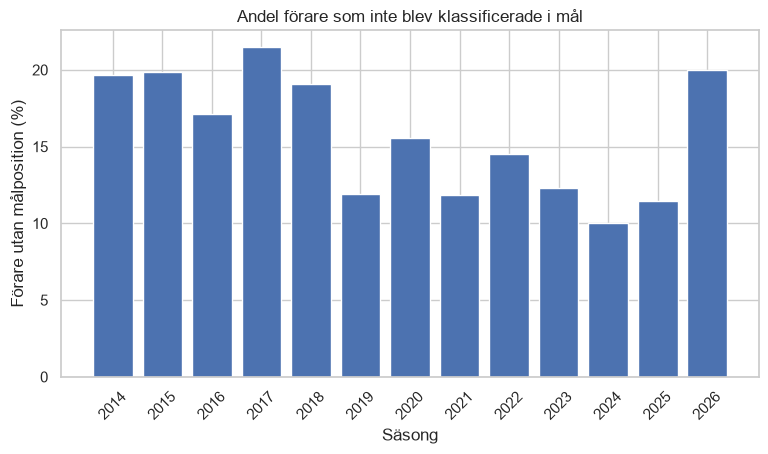

In [16]:
# Andel förare utan målposition (%) per säsong
not_classified_by_year = df["position"].isna().groupby(df["year"]).mean() * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(not_classified_by_year.index, not_classified_by_year.values, color="#4C72B0")
ax.set_xlabel("Säsong")
ax.set_ylabel("Förare utan målposition (%)")
ax.set_title("Andel förare som inte blev klassificerade i mål")
ax.set_xticks(not_classified_by_year.index)
ax.tick_params(axis="x", rotation=45)
plt.show()

**Tolkning:** Mellan 10 % och 21,5 % av förarna blev inte klassificerade i ett lopp, beroende på säsong. Det var högst 2017 (21,5 %) och lägst 2024 (10,0 %). Det betyder att tillförlitlighet och olyckor tar bort en betydande del av förarna varje lopp, och det är en slumpfaktor som ingen modell kan förutsäga utifrån informationen före start. Det sätter en gräns för hur bra modellen kan bli.

### 3.4 Stallens styrka över tid

I Formel 1 spelar bilen minst lika stor roll som föraren. Jag undersöker därför hur pallplatserna har fördelats mellan stallen. Värmekartan visar antalet pallplatser per säsong för de sex stall som tagit flest pallplatser under perioden. Observera att ett stall kan byta namn (t.ex. Force India, Racing Point och Aston Martin), och att datasetet då ser dem som olika stall.

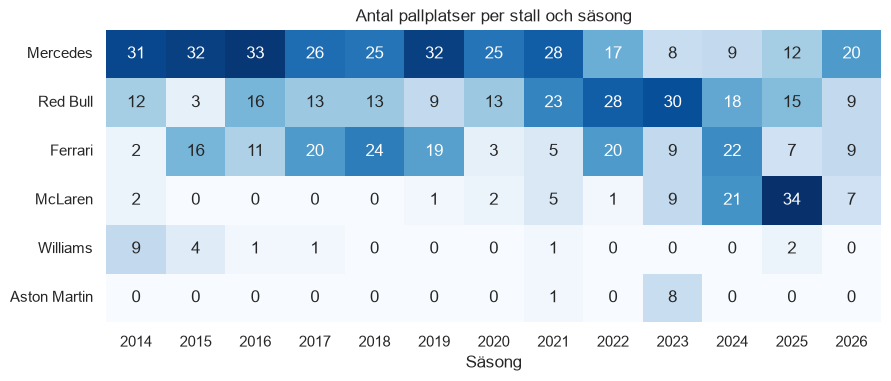

In [17]:
# De sex stall som tagit flest pallplatser under perioden
podiums_by_team = (
    df[df["podium"] == 1]
    .groupby("constructor_name")
    .size()
    .sort_values(ascending=False)
)
top_teams = podiums_by_team.head(6).index

# Tabell: antal pallplatser per stall (rader) och säsong (kolumner)
team_season = (
    df[(df["podium"] == 1) & (df["constructor_name"].isin(top_teams))]
    .pivot_table(index="constructor_name", columns="year", values="podium",
                 aggfunc="sum", fill_value=0)
    .reindex(top_teams)
)

fig, ax = plt.subplots(figsize=(10, 3.8))
sns.heatmap(team_season, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_xlabel("Säsong")
ax.set_ylabel("")
ax.set_title("Antal pallplatser per stall och säsong")
plt.show()

Värmekartan ovan visar mängden pallplatser, men det är svårt att följa ett enskilt stalls utveckling. Linjediagrammet nedan visar de fyra stallen med flest pallplatser. Här har jag använt stallens färger, eftersom färgen i det här diagrammet säger *vilket stall* linjen tillhör. Färgerna är justerade så att de syns tydligt mot den vita bakgrunden. Namnen står direkt vid linjerna, så att diagrammet går att tolka även utan färger. Säsongen 2026 är utelämnad eftersom den är ofullständig.

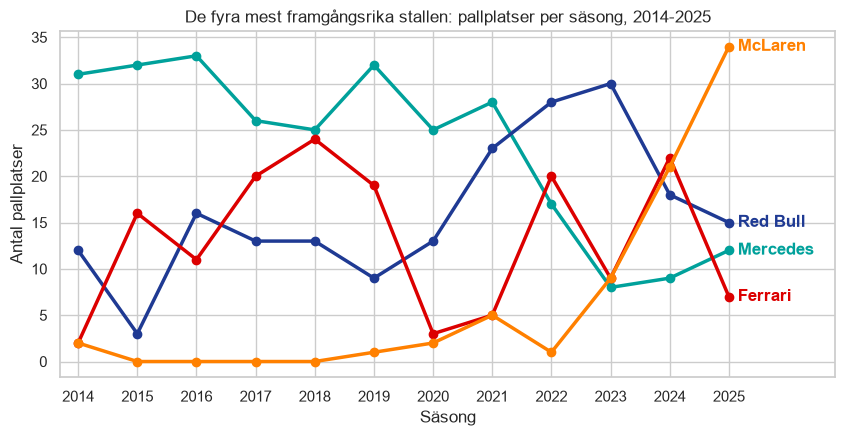

In [18]:
# Stallfärger (justerade för att synas tydligt mot vit bakgrund)
team_colors = {
    "Mercedes": "#00A19B",
    "Red Bull": "#1F3A93",
    "Ferrari": "#DC0000",
    "McLaren": "#FF8000",
}

# 2026 är en ofullständig säsong och lämnas utanför diagrammet
full_seasons = team_season.loc[:, team_season.columns < 2026]

fig, ax = plt.subplots(figsize=(10, 4.5))
for team, color in team_colors.items():
    ax.plot(full_seasons.columns, full_seasons.loc[team], marker="o", color=color, linewidth=2.5)
    # Namnet skrivs direkt vid linjens slut, så att ingen teckenförklaring behövs
    ax.text(full_seasons.columns[-1] + 0.15, full_seasons.loc[team].iloc[-1], team,
            color=color, va="center", fontweight="bold")

ax.set_xlabel("Säsong")
ax.set_ylabel("Antal pallplatser")
ax.set_title("De fyra mest framgångsrika stallen: pallplatser per säsong, 2014-2025")
ax.set_xticks(full_seasons.columns)
ax.set_xlim(full_seasons.columns[0] - 0.3, full_seasons.columns[-1] + 1.8)
plt.show()

**Tolkning:** Pallplatserna är starkt koncentrerade till ett fåtal stall, och vilket stall som dominerar skiftar över tid. Mercedes tog 25-33 pallplatser per säsong 2014-2021, Red Bull dominerade 2022-2023 (28 och 30 pallplatser) och McLaren 2024-2025 (21 och 34). Under en dominerande period är chansen till pallplats mycket högre för ett stalls förare än för andra, oavsett startposition. Det motiverar att jag i modellen tar med stallets **senaste form** och inte bara en fast stallidentitet, och att jag delar upp datan i tid. Namnbyten på stall (t.ex. Aston Martin som tidigare hette Force India och Racing Point) måste jag hantera när jag bygger features.

## 4. Statistiska tester

I EDA såg jag flera samband. Här undersöker jag med statistiska tester om de är statistiskt säkerställda, eller om de lika gärna kan bero på slumpen. För varje test anger jag en nollhypotes (H0), motiverar valet av test och kontrollerar testets antaganden. Jag använder signifikansnivån 5 % (p < 0.05 betyder att jag förkastar H0).

Eftersom datasetet är stort (drygt 5 000 observationer) blir p-värdena ofta extremt små även för små skillnader. Jag redovisar därför också **effektstorlek**, som säger hur stort sambandet är, inte bara om det finns.

In [19]:
import numpy as np
from scipy import stats

ALPHA = 0.05  # signifikansnivå

def fmt_p(p):
    """Formaterar ett p-värde så att mycket små värden skrivs som p < 0.001."""
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

### 4.1 Hänger start på grid 1–3 ihop med pallplats?

- **H0:** Att starta på grid 1-3 och att ta pallplats är oberoende av varandra.
- **H1:** De hänger ihop.
- **Test:** Chi-två-test för oberoende, eftersom båda variablerna är kategoriska (ja/nej) och kan sammanfattas i en 2x2-tabell.
- **Antagande:** Det förväntade antalet i varje ruta ska vara minst 5. Observationerna förutsätts vara oberoende av varandra, vilket inte stämmer helt.
- **Effektstorlek:** phi (0 = inget samband, 1 = perfekt samband) och oddskvot.

In [20]:
# Rader: startade på främre raden (grid 1-3)? Kolumner: tog pallplats?
top3_start = df["grid"].between(1, 3).rename("top3_start")
table = pd.crosstab(top3_start, df["podium"])
print(table)
print()
print((table.div(table.sum(axis=1), axis=0) * 100).round(1))

chi2, p, dof, expected = stats.chi2_contingency(table)
n = table.values.sum()
phi = np.sqrt(chi2 / n)
odds_ratio = (table.loc[True, 1] / table.loc[True, 0]) / (table.loc[False, 1] / table.loc[False, 0])

print(f"\nchi2 = {chi2:.1f}, frihetsgrader = {dof}, {fmt_p(p)}")
print(f"Effektstorlek (phi): {phi:.2f}")
print(f"Oddskvot: {odds_ratio:.1f}")
print(f"Minsta förväntade antal i en ruta: {expected.min():.1f} (ska vara minst 5)")

podium         0    1
top3_start           
False       4386  250
True         248  551

podium         0     1
top3_start            
False       94.6   5.4
True        31.0  69.0

chi2 = 2186.7, frihetsgrader = 1, p < 0.001
Effektstorlek (phi): 0.63
Oddskvot: 39.0
Minsta förväntade antal i en ruta: 117.8 (ska vara minst 5)


**Tolkning:** Av förarna som startade topp 3 tog 69,0 % pallplats, jämfört med 5,4 % av övriga. Chi-två-testet ger χ²(1) = 2186,7 och p < 0.001, så jag förkastar H0: främre raden och pallplats hänger ihop. Effektstorleken är stor (phi = 0,63) och oddsen för pallplats är ungefär 39 gånger högre från främre raden. Antagandet om förväntade antal är uppfyllt (minst 117,8 i varje ruta).

### 4.2 Startar förare som tar pallplats längre fram?

- **Fråga:** Startar förare som tar pallplats längre fram än de som inte gör det?
- **H0:** Det är ingen skillnad i startposition mellan grupperna.
- **H1:** Det är skillnad.
- **Test:** Mann-Whitney U. Jag väljer det i stället för ett t-test, eftersom startposition är en rangordning och inte normalfördelad (se Shapiro-Wilk-testet nedan).
- **Effektstorlek:** Sannolikheten att en förare med pallplats startat före en förare utan pallplats. Den kan också tolkas som ROC-AUC om man bara använder startposition som prognos, och blir en jämförelsepunkt för modellerna senare.

In [21]:
starters = df[df["grid"] >= 1]
podium_grid = starters.loc[starters["podium"] == 1, "grid"]
other_grid = starters.loc[starters["podium"] == 0, "grid"]

print("Median startposition, pallplats:", podium_grid.median())
print("Median startposition, ej pallplats:", other_grid.median())

# Är startposition normalfördelad? (Shapiro-Wilk på ett slumpmässigt urval om 500)
print(stats.shapiro(starters["grid"].sample(500, random_state=42)))

u, p = stats.mannwhitneyu(podium_grid, other_grid, alternative="two-sided")
auc = 1 - u / (len(podium_grid) * len(other_grid))
print(f"U = {u:.0f}, {fmt_p(p)}")
print(f"Sannolikhet att en pallplatsförare startat före en förare utan pallplats: {auc:.1%}")

Median startposition, pallplats: 2.0
Median startposition, ej pallplats: 12.0
ShapiroResult(statistic=np.float64(0.9428981414874922), pvalue=np.float64(6.050367786705743e-13))
U = 289422, p < 0.001
Sannolikhet att en pallplatsförare startat före en förare utan pallplats: 92.1%


**Tolkning:** Mediansstartpositionen är 2 för förare som tog pallplats och 12 för övriga. Shapiro-Wilk förkastar normalfördelning (p < 0.001), vilket motiverar Mann-Whitney U. Testet ger p < 0.001, så jag förkastar H0: startpositionen skiljer sig tydligt åt. I 92,1 % av jämförelserna hade pallplatsföraren startat före den andra föraren. Det betyder att **startposition ensam redan är en mycket stark prognos** (motsvarande ROC-AUC ≈ 0,92), och att mina modeller måste prestera bättre än så för att tillföra något.

### 4.3 Hur starkt hänger startposition och målposition ihop?

- **H0:** Det finns ingen monoton korrelation mellan startposition och målposition (ρ = 0).
- **H1:** Det finns en korrelation.
- **Test:** Spearmans rangkorrelation. Den passar för rangordnade variabler och mäter om högre startnummer tenderar att ge högre slutnummer, utan att kräva ett linjärt samband eller normalfördelning.
- Endast förare som startade från grid 1 eller längre bak och blev klassificerade i mål ingår (annars saknas målposition).

In [22]:
classified = df[(df["grid"] >= 1) & df["position"].notna()]
rho, p = stats.spearmanr(classified["grid"], classified["position"])
print(f"Spearman rho = {rho:.2f}, {fmt_p(p)}, n = {len(classified)}")

Spearman rho = 0.76, p < 0.001, n = 4533


**Tolkning:** Spearmans ρ är 0,76 (p < 0.001, n = 4 533), så jag förkastar H0. Det finns en stark positiv korrelation: den som startar långt bak slutar oftast också långt bak. Sambandet är starkt men inte perfekt, eftersom förare ibland kör upp eller tappar många platser. Det lämnar utrymme för att andra faktorer, som stallets styrka, förklarar något mer.

### 4.4 Varierar andelen segrar från pole mellan säsongerna?

I 3.2 såg det ut som att andelen polesittare som vann varierade mycket mellan säsongerna (38-67 %). Jag testar om skillnaden är statistiskt säkerställd.

- **H0:** Andelen polesittare som vinner är lika stor i alla säsonger.
- **H1:** Andelen skiljer sig mellan minst två säsonger.
- **Test:** Chi-två-test på en tabell med säsong (13 rader) och vann/vann inte (2 kolumner).
- **Antagande:** Förväntat antal minst 5 i varje ruta. Jag redovisar också ett 95 %-igt konfidensintervall för den totala andelen.

In [23]:
# pole skapades i avsnitt 3.2 (förare som startade från grid 1, med kolumnen "won")
table = pd.crosstab(pole["year"], pole["won"])
chi2, p, dof, expected = stats.chi2_contingency(table)
print(f"chi2 = {chi2:.2f}, frihetsgrader = {dof}, {fmt_p(p)}")
print(f"Minsta förväntade antal i en ruta: {expected.min():.1f}")

ci = stats.binomtest(int(pole["won"].sum()), len(pole)).proportion_ci(method="wilson")
print(f"95 % konfidensintervall för andelen segrar från pole: {ci.low:.1%} - {ci.high:.1%}")

chi2 = 8.93, frihetsgrader = 12, p = 0.709
Minsta förväntade antal i en ruta: 6.9
95 % konfidensintervall för andelen segrar från pole: 48.3% - 60.2%


**Tolkning:** Testet ger χ²(12) = 8,93 och p = 0,709, så jag **kan inte förkasta H0**. Skillnaderna mellan säsongerna är förenliga med slumpen, vilket är rimligt eftersom varje säsong bara har 15-24 polepositioner. Det betyder inte att säsongerna *är* lika, bara att datan inte räcker för att visa en skillnad. Minsta förväntade antal i en ruta är 6,9, vilket uppfyller kravet på minst 5, så chi-två-testet är lämpligt. Den totala andelen segrar från pole är 54,3 % med ett 95 %-igt konfidensintervall på 48,3-60,2 %. Det är ett exempel på att en iakttagelse i ett diagram inte alltid håller för ett statistiskt test.

### 4.5 Sammanfattning: vad betyder testerna för modelleringen?

| Test | Fråga | Resultat | Konsekvens |
|---|---|---|---|
| Chi-två (4.1) | Topp 3 på griden och pallplats | Stort samband (phi 0,63, p < 0.001) | Startposition är en nyckelfeature |
| Mann-Whitney U (4.2) | Startposition, pallplats mot övriga | p < 0.001, ROC-AUC ≈ 0,92 | Startposition ensam är en stark baslinje som modellerna måste slå |
| Spearman (4.3) | Start- och målposition | ρ = 0,76 (p < 0.001) | Starkt men inte perfekt samband, det finns plats för fler features |
| Chi-två (4.4) | Pole-vinst mellan säsonger | p = 0,709 | Ingen säkerställd skillnad mellan säsonger |

**Begränsningar:** Testerna förutsätter oberoende observationer, men förare i samma lopp påverkas av samma förhållanden (väder, olyckor) och samma förare förekommer många gånger. P-värdena är därför troligen något för optimistiska. Eftersom p-värdena i 4.1-4.3 är extremt små påverkas slutsatserna inte av att jag gör flera tester, men effektstorlekarna är viktigare att fokusera på än p-värdena.

## 5. Preprocessing och features

Här bygger jag de variabler (features) som modellen ska använda för att förutsäga pallplats. Den viktigaste regeln är att **modellen bara får använda sådant som är känt före loppets start**. Använder den information från själva loppet (till exempel poäng, antal varv eller hur loppet slutade) "fuskar" den, eftersom svaret då redan finns i datan. Det kallas **dataläckage** och ger modeller som ser bra ut i testet men inte fungerar på riktigt.

| Får användas (känt före start) | Får **inte** användas (känt först efter loppet) |
|---|---|
| Startposition, kvaltider, kvalposition | `points`, `position`, `positionOrder` i samma lopp |
| Förarens och stallets resultat i **tidigare** lopp | `laps`, `time`, `fastestLap`, `statusId` i samma lopp |

De flesta features är därför "form" över tid, och de räknas alltid bara från loppen **före** det aktuella loppet.

### 5.2 Startposition (grid)

Förare som startar från depån har `grid = 0` i datan. Det betyder inte att de står först, utan tvärtom: de startar efter alla andra. Om `0` används som vanligt tal tolkar modellen dem som bäst placerade, vilket är fel. Jag skapar därför `grid_adj`, där depåstarter placeras sist, det vill säga på platsen efter sista föraren i loppet.

In [24]:
# Antal förare i varje lopp (används för att placera depåstarter sist)
starters_per_race = df.groupby("raceId")["grid"].transform("size")

# Behåll grid om den är större än 0, annars sätt platsen efter sista föraren
df["grid_adj"] = df["grid"].where(df["grid"] > 0, starters_per_race + 1)

print("Depåstarter före och efter justering:")
print(df.loc[df["grid"] == 0, ["driver", "year", "grid", "grid_adj"]].head(3))

Depåstarter före och efter justering:
                driver  year  grid  grid_adj
22551  Valtteri Bottas  2015     0        19
22571     Will Stevens  2015     0        21
22641     Carlos Sainz  2015     0        21


### 5.3 Kvalresultat

Från tabellen `qualifying` skapar jag tre features:

- **`quali_best`**: förarens snabbaste kvaltid i sekunder. Tiderna är text som `1:26.572`, så jag gör först om dem till tal med en funktion. Kvalet har tre omgångar (Q1-Q3) och förare som åker ut tidigt har bara tider från de första, så jag tar den snabbaste tid de faktiskt har.
- **`gap_to_pole_pct`**: hur mycket långsammare föraren var än den snabbaste i samma lopp, i procent. Procent (och inte sekunder) gör det jämförbart mellan korta och långa banor.
- **`grid_vs_quali`**: startposition minus kvalposition. Värdet är 0 för de flesta, positivt om föraren startar längre bak än kvalet gav (till exempel på grund av straff) och negativt om föraren flyttas upp.

**Begränsning:** Förare som åker ut i Q1 jämförs med polesittarens tid från Q3, då banan oftast är snabbare, så deras gap överskattas något.

In [25]:
def time_to_seconds(t):
    """Gör om en tid som '1:26.572' till sekunder (86.572). Saknade värden förblir NaN."""
    if pd.isna(t):
        return np.nan
    minutes, seconds = t.split(":")
    return int(minutes) * 60 + float(seconds)

quali = qualifying[["raceId", "driverId", "position", "q1", "q2", "q3"]].copy()
for col in ["q1", "q2", "q3"]:
    quali[col] = quali[col].map(time_to_seconds)

# Snabbaste tiden bland Q1, Q2 och Q3 (saknade tider hoppas över)
quali["quali_best"] = quali[["q1", "q2", "q3"]].min(axis=1)
quali = quali.rename(columns={"position": "quali_position"})

# Lägg till i analystabellen
df = df.merge(quali[["raceId", "driverId", "quali_position", "quali_best"]],
              on=["raceId", "driverId"], how="left", validate="one_to_one")

# Avstånd till den snabbaste tiden i loppet, i procent
pole_time = df.groupby("raceId")["quali_best"].transform("min")
df["gap_to_pole_pct"] = (df["quali_best"] / pole_time - 1) * 100

# Skillnad mellan startposition och kvalposition (straff, nedflyttningar)
df["grid_vs_quali"] = df["grid_adj"] - df["quali_position"]

print(df[["gap_to_pole_pct", "grid_vs_quali"]].describe().round(2))
print()
print("Saknade värden:")
print(df[["quali_position", "gap_to_pole_pct", "grid_vs_quali"]].isna().sum())

       gap_to_pole_pct  grid_vs_quali
count          5334.00        5413.00
mean              2.13           0.04
std               2.34           1.81
min               0.00          -8.00
25%               0.86           0.00
50%               1.76           0.00
75%               2.75           0.00
max              45.60          19.00

Saknade värden:
quali_position      22
gap_to_pole_pct    101
grid_vs_quali       22
dtype: int64


**Saknade värden:** Jag fyller inte i saknade kvaltider nu. Det görs i modelleringsfasen, där ersättningsvärdet räknas ut **bara från träningsdatan**, annars skulle information från testperioden läcka in. Några förare har dessutom mycket stora gap (upp till 45 %), vilket jag tar hänsyn till när jag väljer modeller.

### 5.4 Förarens form

Förarens senaste resultat säger något om hur bra förare och bil är just nu. Jag skapar två features:

- **`driver_avg_finish_5`**: förarens genomsnittliga målposition de **senaste fem loppen**. Förare som bröt loppet har en placering efter alla som kom i mål (`positionOrder`), så avbrutna lopp drar ner snittet.
- **`driver_podium_rate_5`**: andelen av de senaste fem loppen där föraren tog pallplats.

Två val som är viktiga för att undvika dataläckage och felaktiga värden:
- `shift(1)` flyttar värdena ett lopp framåt, så att det aktuella loppets eget resultat **aldrig** ingår i sin egen feature.
- Jag räknar formen på all historik (inte bara 2014 och framåt), så att de första loppen 2014 också får ett värde baserat på 2013. `min_periods=3` kräver minst tre tidigare lopp, annars blir värdet saknat. Då blir inga snitt baserade på bara ett lopp.

Några gamla lopp (1950-1960) har dubbletter för samma förare, eftersom förare delade bil. De tas bort, och det påverkar inte analysen av nyare säsonger.

In [26]:
# Hela historiken, med datum, så att formen kan räknas över säsongsgränser
full = results.merge(races[["raceId", "year", "date"]], on="raceId", how="left")
full["date"] = pd.to_datetime(full["date"])
full["podium"] = (full["position"] <= 3).astype(int)

# Några gamla lopp har samma förare två gånger (delad bil): behåll en rad
full = full.drop_duplicates(["raceId", "driverId"])

# Sortera i tidsordning per förare
full = full.sort_values(["driverId", "date", "raceId"])

# Snitt över de 5 föregående loppen (shift(1) utesluter det aktuella loppet)
by_driver = full.groupby("driverId")
full["driver_avg_finish_5"] = by_driver["positionOrder"].transform(
    lambda s: s.shift(1).rolling(5, min_periods=3).mean())
full["driver_podium_rate_5"] = by_driver["podium"].transform(
    lambda s: s.shift(1).rolling(5, min_periods=3).mean())

# Lägg till i analystabellen
df = df.merge(full[["raceId", "driverId", "driver_avg_finish_5", "driver_podium_rate_5"]],
              on=["raceId", "driverId"], how="left", validate="one_to_one")

**Kontrollcell:** Stämmer featuren?

In [27]:
hamilton = full[full["driverId"] == 1].reset_index(drop=True)
i = hamilton[hamilton["year"] == 2016].index[8]   # hans 9:e lopp 2016

print("Föregående 5 placeringar:", hamilton.loc[i-5:i-1, "positionOrder"].tolist())
print("Deras snitt:", hamilton.loc[i-5:i-1, "positionOrder"].mean())
print("Featurens värde i loppet:", hamilton.loc[i, "driver_avg_finish_5"])
print("Pallplatser senaste 5:", hamilton.loc[i-5:i-1, "podium"].tolist(),
      "->", hamilton.loc[i, "driver_podium_rate_5"])

Föregående 5 placeringar: [2, 21, 1, 1, 5]
Deras snitt: 6.0
Featurens värde i loppet: 6.0
Pallplatser senaste 5: [1, 0, 1, 1, 0] -> 0.6


**Kontrollcell:** hur hänger featuresen ihop med pallplats?

In [28]:
print(len(df))   # ska fortfarande vara 5435 rader
print(df[["driver_avg_finish_5", "driver_podium_rate_5"]].isna().sum())
df[["podium", "grid_adj", "gap_to_pole_pct", "grid_vs_quali",
    "driver_avg_finish_5", "driver_podium_rate_5"]].corr()["podium"].round(2)

5435
driver_avg_finish_5     121
driver_podium_rate_5    121
dtype: int64


podium                  1.00
grid_adj               -0.52
gap_to_pole_pct        -0.29
grid_vs_quali           0.00
driver_avg_finish_5    -0.51
driver_podium_rate_5    0.58
Name: podium, dtype: float64

#### Korrelationerna som diagram

Siffrorna i tabellen blir lättare att tolka som ett diagram. Varje stapel visar hur starkt en feature hänger ihop med pallplats (från -1 till 1). Staplar åt höger (blå) betyder att högre värde ger större chans till pallplats, och staplar åt vänster (orange) att högre värde ger mindre chans. Ju längre stapeln är, desto starkare samband. För startposition och snittplacering är ett *högre* tal sämre (plats 15 är sämre än plats 2), därför är de negativa.

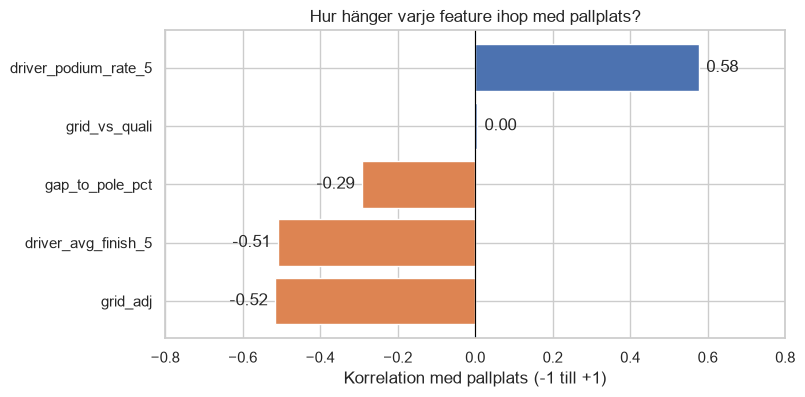

In [29]:
# De features som hittills har skapats
features = ["grid_adj", "gap_to_pole_pct", "grid_vs_quali",
            "driver_avg_finish_5", "driver_podium_rate_5"]

# Korrelation mellan varje feature och pallplats, sorterad från minst till störst
corr_with_podium = df[["podium"] + features].corr()["podium"].drop("podium").sort_values()

# Blå = positivt samband, orange = negativt samband
colors = ["#DD8452" if v < 0 else "#4C72B0" for v in corr_with_podium]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(corr_with_podium.index, corr_with_podium.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-0.8, 0.8)
ax.set_xlabel("Korrelation med pallplats (-1 till +1)")
ax.set_title("Hur hänger varje feature ihop med pallplats?")
for y, v in enumerate(corr_with_podium.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), y, f"{v:.2f}",
            va="center", ha="left" if v >= 0 else "right")
plt.show()

**Tolkning:** Antalet rader är oförändrat (5 435), så sammanslagningarna har inte lagt till eller tagit bort något. 121 rader saknar förarens form, vilket är nya förare och deras första lopp (färre än tre tidigare lopp), och de fylls i vid modelleringen. Korrelationen med pallplats visar att förarens form är lika informativ som startpositionen: `driver_podium_rate_5` (+0,58), `grid_adj` (−0,52) och `driver_avg_finish_5` (−0,51) är alla starka, medan `gap_to_pole_pct` (−0,29) är måttlig. Tecknen är rimliga: högre startnummer och sämre form ger lägre chans till pallplats. `grid_vs_quali` har ingen linjär korrelation (0,00), men jag behåller den eftersom den kan ha betydelse tillsammans med andra features. Korrelation mäter bara linjära samband och säger inget om orsak. Dessutom hänger featuresna ihop med varandra (en förare i bra form startar ofta långt fram), vilket jag tar hänsyn till när jag tolkar modellen i kapitel 7.

### 5.5 Stallets form

Bilen betyder minst lika mycket som föraren, så jag skapar samma slags formfeatures för stallet som för föraren:

- **`team_avg_finish_5`**: stallets genomsnittliga placering (för båda bilarna) de senaste fem loppen.
- **`team_podium_rate_5`**: andelen av stallets bilar som tog pallplats de senaste fem loppen (0 = ingen, 1 = båda bilarna i varje lopp).

**Problem: stall byter namn.** I datan får ett stall ett nytt `constructorId` när det byter namn, till exempel Force India, Racing Point och Aston Martin. Då skulle stallets form "nollställas" vid varje namnbyte, trots att det är samma fabrik och samma team. Jag kopplar därför ihop namnbytena till ett gemensamt `team_id`:

| Stall (kedja) | Namn i datan |
|---|---|
| Force India | Force India → Racing Point → Aston Martin |
| Toro Rosso | Toro Rosso → AlphaTauri → RB F1 Team |
| Sauber | Sauber → Alfa Romeo → Sauber → Audi |
| Lotus/Renault | Lotus F1 → Renault → Alpine |
| Marussia | Marussia → Manor Marussia |

Övriga stall behåller sitt eget id. Det är en förenkling, eftersom ägare och resurser ibland ändras vid ett namnbyte (till exempel när Audi tog över Sauber 2026), men fabriken och personalen är i huvudsak desamma. Formen räknas på all historik och med `shift(1)` på samma sätt som för förarna, så att det aktuella loppet aldrig ingår i sin egen feature.

In [30]:
# Koppla ihop stall som bytt namn till ett gemensamt team_id
TEAM_LINEAGE = {
    211: 10,    # Racing Point   -> Force India
    117: 10,    # Aston Martin   -> Force India
    213: 5,     # AlphaTauri     -> Toro Rosso
    215: 5,     # RB F1 Team     -> Toro Rosso
    51: 15,     # Alfa Romeo     -> Sauber
    216: 15,    # Audi           -> Sauber
    4: 208,     # Renault        -> Lotus F1
    214: 208,   # Alpine         -> Lotus F1
    209: 206,   # Manor Marussia -> Marussia
}

# Stall som inte finns i listan behåller sitt eget id
df["team_id"] = df["constructorId"].map(TEAM_LINEAGE).fillna(df["constructorId"]).astype(int)
full["team_id"] = full["constructorId"].map(TEAM_LINEAGE).fillna(full["constructorId"]).astype(int)

# Kontroll: antal olika stall per säsong (ska vara 10-11)
print(df.groupby("year")["team_id"].nunique().to_dict())

# Ett resultat per stall och lopp: snittplacering och andel pallplatser för stallets bilar
team_race = (
    full.groupby(["team_id", "raceId", "date"], as_index=False)
        .agg(avg_finish=("positionOrder", "mean"), podium_rate=("podium", "mean"))
        .sort_values(["team_id", "date", "raceId"])
)

# Snitt över de 5 föregående loppen (shift(1) utesluter det aktuella loppet)
by_team = team_race.groupby("team_id")
team_race["team_avg_finish_5"] = by_team["avg_finish"].transform(
    lambda s: s.shift(1).rolling(5, min_periods=3).mean())
team_race["team_podium_rate_5"] = by_team["podium_rate"].transform(
    lambda s: s.shift(1).rolling(5, min_periods=3).mean())

# Lägg till i analystabellen
df = df.merge(team_race[["team_id", "raceId", "team_avg_finish_5", "team_podium_rate_5"]],
              on=["team_id", "raceId"], how="left", validate="many_to_one")

{2014: 11, 2015: 10, 2016: 11, 2017: 10, 2018: 10, 2019: 10, 2020: 10, 2021: 10, 2022: 10, 2023: 10, 2024: 10, 2025: 10, 2026: 11}


**Kontrollcell:** Mercedes, Österrike 2016

In [31]:
race_id = races[(races["year"] == 2016) & (races["name"] == "Austrian Grand Prix")]["raceId"].iloc[0]
mercedes = team_race[team_race["team_id"] == 131].reset_index(drop=True)
i = mercedes.index[mercedes["raceId"] == race_id][0]

print("Stallets snittplacering i de 5 föregående loppen:", mercedes.loc[i-5:i-1, "avg_finish"].tolist())
print("Deras snitt:", round(mercedes.loc[i-5:i-1, "avg_finish"].mean(), 2))
print("Featurens värde i loppet:", round(mercedes.loc[i, "team_avg_finish_5"], 2))
print("Andel pallplatser senaste 5:", mercedes.loc[i-5:i-1, "podium_rate"].tolist(),
      "->", mercedes.loc[i, "team_podium_rate_5"])

Stallets snittplacering i de 5 föregående loppen: [1.5, 21.5, 4.0, 3.0, 3.0]
Deras snitt: 6.6
Featurens värde i loppet: 6.6
Andel pallplatser senaste 5: [1.0, 0.0, 0.5, 0.5, 0.5] -> 0.5


**Tolkning:** Kontrollen visar att stallets form räknas rätt och bara bygger på tidigare lopp: Mercedes fem lopp före Österrike 2016 gav snittplaceringen 6,6 (där Spanien, då båda bilarna föll ur, drar upp snittet) och pallplatsandelen 0,5. Antalet stall per säsong (10-11) stämmer med verkligheten, vilket visar att namnbytena är korrekt ihopkopplade. Endast 12 rader saknar stallform, och det gäller nya stall i sina tre första lopp (Haas 2016 och Cadillac 2026).

#### Hänger featuresna ihop med varandra?

Värmekartan visar korrelationen mellan alla sju features. Det är viktigt att veta, eftersom features som mäter ungefär samma sak inte tillför mycket ny information var för sig. Rött betyder att två features ökar tillsammans, blått att den ena ökar när den andra minskar, och ju starkare färg, desto starkare samband.

In [32]:
df[["driver_avg_finish_5", "team_avg_finish_5",
    "driver_podium_rate_5", "team_podium_rate_5"]].corr().round(2)

,driver_avg_finish_5,team_avg_finish_5,driver_podium_rate_5,team_podium_rate_5
driver_avg_finish_5,1.00,0.91,-0.77,-0.74
team_avg_finish_5,0.91,1.00,-0.73,-0.81
driver_podium_rate_5,-0.77,-0.73,1.00,0.89
team_podium_rate_5,-0.74,-0.81,0.89,1.00


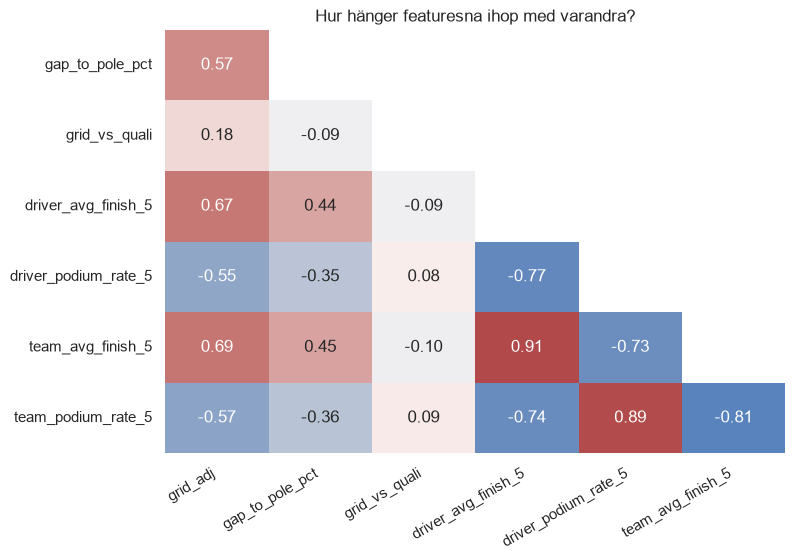

In [33]:
# Alla sju features (samma lista som i avsnitt 5.6)
features = ["grid_adj", "gap_to_pole_pct", "grid_vs_quali",
            "driver_avg_finish_5", "driver_podium_rate_5",
            "team_avg_finish_5", "team_podium_rate_5"]

corr_matrix = df[features].corr()

# Visa bara nedre triangeln (varje par en gång) och ta bort tom rad och kolumn
corr_lower = corr_matrix.iloc[1:, :-1]
mask = np.triu(np.ones_like(corr_lower, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(corr_lower, mask=mask, annot=True, fmt=".2f", cmap="vlag",
            vmin=-1, vmax=1, cbar=False, ax=ax)
ax.grid(False)
ax.set_title("Hur hänger featuresna ihop med varandra?")
ax.tick_params(axis="x", rotation=30)
plt.setp(ax.get_xticklabels(), ha="right")
plt.show()

**Tolkning:** Förarens och stallets form hänger mycket starkt ihop (0,91 för snittplacering och 0,89 för andel pallplatser). Det är rimligt, eftersom en förares resultat till stor del avgörs av bilen. Det betyder att featuresna delvis mäter samma sak. Det är inget fel, men det påverkar tolkningen av modellen: när två features är så lika kan modellen fördela vikten mellan dem, och det blir svårt att säga hur mycket just föraren eller just bilen betyder. Det tar jag upp i kapitel 7.

### 5.6 Uppdelning i träning, validering och test

Jag delar upp datan i **tre delar efter tid**:

| Del | Säsonger | Används till |
|---|---|---|
| Träning (train) | 2014-2022 | Modellen lär sig mönster |
| Validering (valid) | 2023-2024 | Jämföra modeller och välja inställningar |
| Test (test) | 2025-2026 | Slutlig, ärlig utvärdering. Används **en enda gång** i slutet |

Varför uppdelning efter tid och inte slumpmässigt? Modellen ska i verkligheten förutsäga *framtida* lopp utifrån det förflutna. Med en slumpmässig uppdelning skulle förare från samma lopp hamna både i träningen och i testet, och formfeaturena skulle överlappa, så modellen får se information från framtiden. Då blir resultaten för bra och missvisande. Med tidsuppdelning efterliknar jag hur modellen skulle användas på riktigt.

Testdelen rörs inte förrän all modellering är klar. Om jag justerade modellen efter testresultatet skulle det inte längre vara ett ärligt test. Observera att 2026 är en ofullständig säsong (15 lopp).

In [34]:
# Dela upp efter säsong
train = df[df["year"] <= 2022]
valid = df[df["year"].between(2023, 2024)]
test = df[df["year"] >= 2025]

for name, part in [("train", train), ("valid", valid), ("test", test)]:
    print(f"{name:<6}{len(part):>6} rader {part['raceId'].nunique():>4} lopp  "
          f"säsonger {part['year'].min()}-{part['year'].max()}  "
          f"andel pallplats {part['podium'].mean():.1%}")

# Indata (X) och målvariabel (y) för varje del
X_train, y_train = train[features], train["podium"]
X_valid, y_valid = valid[features], valid["podium"]
X_test, y_test = test[features], test["podium"]

train   3707 rader  182 lopp  säsonger 2014-2022  andel pallplats 14.7%
valid    919 rader   46 lopp  säsonger 2023-2024  andel pallplats 15.0%
test     809 rader   39 lopp  säsonger 2025-2026  andel pallplats 14.5%


**Tolkning:** Träningsdelen har 3 707 rader (182 lopp), valideringsdelen 919 (46 lopp) och testdelen 809 (39 lopp). Andelen pallplatser är nästan lika stor i alla tre delarna (14,5-15,0 %), vilket är väntat eftersom tre av ungefär tjugo förare alltid hamnar på pallen. Det betyder att uppdelningen inte har gjort någon del orättvist svår eller lätt.

### 5.7 Saknade värden i featuresna

Några features saknar värden. Jag fyller inte i dem här, utan i modelleringen i kapitel 6, där ersättningsvärdet (till exempel medianen) räknas ut **enbart från träningsdelen** och sedan används på alla tre delarna. Räknade jag ut det på hela datasetet skulle information från testperioden läcka in i träningen.

In [35]:
# Antal saknade värden per feature och del
pd.DataFrame({
    "train": X_train.isna().sum(),
    "valid": X_valid.isna().sum(),
    "test": X_test.isna().sum(),
})

,train,valid,test
grid_adj,0,0,0
gap_to_pole_pct,58,9,34
grid_vs_quali,16,0,6
driver_avg_finish_5,89,18,14
driver_podium_rate_5,89,18,14
team_avg_finish_5,6,0,6
team_podium_rate_5,6,0,6


**Tolkning:** Saknade värden är få i förhållande till datamängden (högst 89 av 3 707 rader i träningsdelen) och har tydliga orsaker: nya förare och stall som saknar tre tidigare lopp (formfeatures), samt förare som inte satte någon kvaltid (`gap_to_pole_pct`). I testdelen saknas till exempel Miami 2025 helt, eftersom kvaltiderna saknas i datan. Eftersom bara en liten andel av raderna påverkas tar jag inte bort dem, utan fyller i dem i kapitel 6.

## 6. Modeller och jämförelse

Nu tränar jag modeller som förutsäger pallplats, och jämför dem med enkla baslinjer. Alla modeller tränas på träningsdelen (2014-2022) och jämförs på valideringsdelen (2023-2024). **Testdelen (2025-2026) rörs inte** förrän modellvalet är klart.

Jag jämför tre modeller med olika komplexitet:

| Modell | Kort förklaring |
|---|---|
| **Logistisk regression** | Väger ihop featuresna med en vikt var och räknar ut en sannolikhet. Enkel och lätt att tolka. |
| **Random forest** | Många beslutsträd som tränas på olika slumpmässiga delar av datan och sedan "röstar". Kan fånga samspel mellan features. |
| **LightGBM (gradient boosting)** | Beslutsträd som byggs efter varandra, där varje nytt träd försöker rätta till föregående träds misstag. Ofta mycket träffsäker, men kan överanpassa. |

Alla modeller får samma förbehandling i en s.k. *pipeline*: saknade värden ersätts med medianen **från träningsdatan** (så att ingen information från valideringen läcker in), och för logistisk regression standardiseras featuresna också (de har olika skalor, till exempel placering 1-20 jämfört med andel 0-1). Trädbaserade modeller behöver ingen standardisering.

### 6.1 Hur utvärderar jag modellerna?

Eftersom bara cirka 15 % av förarna tar pallplats är *accuracy* (andel rätt) ett dåligt mått. Modellen i nästa steg gissar alltid "ingen pallplats" och får ändå ungefär 85 % rätt, utan att hitta en enda pallplats. Jag använder i stället:

| Mått | Vad det betyder |
|---|---|
| **ROC-AUC** | Sannolikheten att en slumpmässig pallplatsförare får högre poäng än en slumpmässig förare utan pallplats. 0,5 = slump, 1,0 = perfekt. |
| **PR-AUC** | Fokuserar på pallplatserna: hur väl modellen hittar dem utan att peka ut för många fel. Känsligare än ROC-AUC när klasserna är obalanserade (slumpnivån är här cirka 0,15). |
| **top3_hit_rate** | I varje lopp pekar jag ut de **tre förare** som modellen ger högst sannolikhet. Måttet är andelen av dessa som verkligen tog pallplats. Det är ett lättförståeligt mått, eftersom det alltid är exakt tre pallplatser per lopp. |
| **all_three_correct** | Andelen lopp där alla tre utpekade förare stod på pallen. |

Som jämförelse, **baslinjen**, använder jag startposition: förarna längst fram förutsägs oftast stå på pallen. Den modellen måste vara bättre än så för att göra nytta.

In [36]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, average_precision_score


def top3_metrics(data, proba):
    """Väljer de 3 förare per lopp med högst poäng och räknar hur många som verkligen tog pallplats."""
    tmp = data[["raceId", "podium"]].copy()
    tmp["score"] = np.asarray(proba)
    tmp["rank"] = tmp.groupby("raceId")["score"].rank(method="first", ascending=False)
    hits = tmp[tmp["rank"] <= 3].groupby("raceId")["podium"].sum()   # antal rätt per lopp (0-3)
    return hits.mean() / 3, (hits == 3).mean()


def evaluate(name, data, y, score):
    """Samlar alla mått för en modell i en rad."""
    top3_hit_rate, all_three_correct = top3_metrics(data, score)
    return {
        "model": name,
        "roc_auc": roc_auc_score(y, score),
        "pr_auc": average_precision_score(y, score),
        "top3_hit_rate": top3_hit_rate,
        "all_three_correct": all_three_correct,
    }

### 6.2 Baslinjer

Jag börjar med två enkla jämförelser. Den första är en modell som **alltid gissar "ingen pallplats"**. Den visar varför accuracy är vilseledande. Den andra är **startposition**: ju längre fram en förare startar, desto högre poäng. Det är en enkel regel utan någon maskininlärning, och den modell jag måste slå. Poängen är `-grid_adj`, minustecknet gör att en lägre startplats får en högre poäng.

In [37]:
# Baslinje 1: gissa alltid "ingen pallplats"
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred = dummy.predict(X_valid)
print(f"Accuracy: {accuracy_score(y_valid, pred):.1%}")
print(f"Recall (andel pallplatser som hittas): {recall_score(y_valid, pred):.1%}")

# Baslinje 2: startposition. Resultaten samlas i en lista som fylls på för varje modell.
results = []
results.append(evaluate("Baslinje: startposition", valid, y_valid, -valid["grid_adj"]))
models = {}

Accuracy: 85.0%
Recall (andel pallplatser som hittas): 0.0%


**Tolkning:** Modellen som alltid gissar "ingen pallplats" får 85,0 % i accuracy men hittar inte en enda pallplats (recall 0 %). Det bekräftar att accuracy inte duger som mått här, och att jag i stället använder ROC-AUC, PR-AUC och träffsäkerhet bland de tre utpekade förarna per lopp.

### 6.3 Logistisk regression

Den enklaste modellen och en bra första jämförelse. Pipelinen fyller först i saknade värden med medianen, standardiserar featuresna och tränar sedan modellen. `predict_proba(...)[:, 1]` ger sannolikheten för klass 1 (pallplats), och den används som "poäng" för att rangordna förarna.

In [38]:
log_reg = make_pipeline(
    SimpleImputer(strategy="median"),     # fyller i saknade värden (median från träningsdatan)
    StandardScaler(),                     # ger features jämförbar skala
    LogisticRegression(max_iter=1000),
)
log_reg.fit(X_train, y_train)
models["Logistisk regression"] = log_reg
results.append(evaluate("Logistisk regression", valid, y_valid, log_reg.predict_proba(X_valid)[:, 1]))

### 6.4 Random forest

Random forest består av många beslutsträd som tränas på olika slumpmässiga delar av datan, och deras svar slås ihop. Det gör modellen mer stabil än ett enda träd. Jag använder 300 träd, och `min_samples_leaf=5` innebär att varje löv måste bygga på minst fem observationer, vilket motverkar överanpassning. `random_state=42` gör att resultatet blir detsamma varje gång notebooken körs.

In [39]:
rf = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1),
)
rf.fit(X_train, y_train)
models["Random forest"] = rf
results.append(evaluate("Random forest", valid, y_valid, rf.predict_proba(X_valid)[:, 1]))

### 6.5 LightGBM (gradient boosting)

Här byggs träden efter varandra, och varje nytt träd lär sig av föregående träds fel. Inställningarna är försiktiga för att inte överanpassa: 200 små träd (`num_leaves=15`) med låg inlärningstakt (`learning_rate=0.05`). Jag har inte finjusterat dem än, det görs i nästa avsnitt.

In [40]:
lgbm = make_pipeline(
    SimpleImputer(strategy="median"),
    LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, random_state=42, verbose=-1),
)
lgbm.fit(X_train, y_train)
models["LightGBM"] = lgbm
results.append(evaluate("LightGBM", valid, y_valid, lgbm.predict_proba(X_valid)[:, 1]))

### 6.6 Jämförelse av modellerna

Tabellen visar alla modeller på valideringsdelen (2023-2024, 46 lopp). Jag har också lagt till `roc_auc_train`, ROC-AUC på träningsdatan. Om den är mycket högre än på valideringen har modellen **överanpassat**, det vill säga lärt sig träningsdatan utantill i stället för generella mönster.

In [41]:
results_df = pd.DataFrame(results).set_index("model")

# ROC-AUC på träningsdatan, för att se om modellen överanpassar
results_df["roc_auc_train"] = [roc_auc_score(y_train, -train["grid_adj"])] + [
    roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]) for m in models.values()
]
results_df.round(3)

,roc_auc,pr_auc,top3_hit_rate,all_three_correct,roc_auc_train
model,,,,,
Baslinje: startposition,0.911,0.664,0.659,0.196,0.923
Logistisk regression,0.926,0.726,0.667,0.217,0.939
Random forest,0.929,0.673,0.667,0.217,0.980
LightGBM,0.917,0.647,0.659,0.196,0.985


**Tolkning:** Modellerna presterar bara marginellt bättre än baslinjen som enbart använder startposition (ROC-AUC 0,911). Logistisk regression är bäst på PR-AUC (0,726 jämfört med 0,664), och random forest har högst ROC-AUC (0,929). I praktiken pekar alla modeller ut ungefär två av tre pallplatsförare rätt per lopp (top3_hit_rate 0,66-0,67) och får alla tre rätt i ungefär vart femte lopp (0,20-0,22). Skillnaderna mellan modellerna är små. Valideringsdelen har bara 46 lopp (138 utpekade förare), så en enda förare mer eller mindre rätt ändrar träffsäkerheten med ungefär 0,7 procentenheter. Skillnaderna ligger därför troligen inom slumpens variation.

Random forest och LightGBM har dessutom tydligt överanpassat: ROC-AUC är 0,980 respektive 0,985 på träningsdatan men bara 0,929 och 0,917 på valideringen. Den enklaste modellen, logistisk regression, skiljer sig minst mellan träning (0,939) och validering (0,926), och är samtidigt bäst på PR-AUC.

Att modellerna inte förbättrar mycket är inte konstigt. Startposition fångar redan det mesta av vad som avgör pallplats, och resten bestäms av sådant som är svårt att förutse före loppet, till exempel olyckor, haverier, strategi och väder.

### 6.7 Trimning av modellerna med tidsmedveten korsvalidering

I 6.6 såg jag att random forest och LightGBM överanpassade. Här söker jag efter bättre inställningar (**hyperparametrar**), till exempel hur djupa träden får vara. Att trimma på bara en valideringsperiod (46 lopp) är riskabelt, eftersom jag då kan hitta inställningar som råkar passa just de loppen. Jag använder i stället **korsvalidering över tid** på all utvecklingsdata (2014-2024), där testdelen 2025-2026 fortfarande inte rörs:

| Träning | Validering |
|---|---|
| 2014-2018 | 2019-2020 |
| 2014-2020 | 2021-2022 |
| 2014-2022 | 2023-2024 |

Modellen tränas alltid på **tidigare** säsonger och utvärderas på de följande, precis som i verkligheten. Jag provar alla kombinationer av ett litet rutnät av inställningar (`GridSearchCV`) och väljer den kombination som ger högst PR-AUC i genomsnitt över de tre perioderna. PR-AUC passar bäst eftersom den fokuserar på att hitta pallplatserna. Medianen för saknade värden räknas om inom varje träningsperiod, eftersom hela pipelinen tränas om i varje omgång. Det betyder att ingen information läcker från valideringsperioden.

**Utvecklingsdata och perioder**

In [42]:
from sklearn.model_selection import GridSearchCV

# Utvecklingsdata: 2014-2024 (testdelen 2025-2026 är orörd)
dev = df[df["year"] <= 2024].reset_index(drop=True)
X_dev, y_dev = dev[features], dev["podium"]

# Tre perioder: träna på tidigare säsonger, validera på de två följande
blocks = [(2019, 2020), (2021, 2022), (2023, 2024)]
cv_splits = []
for first, last in blocks:
    train_idx = np.where(dev["year"] < first)[0]
    val_idx = np.where(dev["year"].between(first, last))[0]
    cv_splits.append((train_idx, val_idx))
    print(f"Träning 2014-{first - 1} ({len(train_idx)} rader) -> validering {first}-{last} ({len(val_idx)} rader)")

Träning 2014-2018 (2067 rader) -> validering 2019-2020 (760 rader)
Träning 2014-2020 (2827 rader) -> validering 2021-2022 (880 rader)
Träning 2014-2022 (3707 rader) -> validering 2023-2024 (919 rader)


**Rutnätssökning**

In [43]:
# Modeller och de inställningar som ska provas
candidates = {
    "Logistisk regression": (
        make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)),
        {"logisticregression__C": [0.01, 0.1, 1, 10]},      # C: lägre värde = starkare förenkling
    ),
    "Random forest": (
        make_pipeline(SimpleImputer(strategy="median"),
                      RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=1)),
        {"randomforestclassifier__max_depth": [3, 5, 8],            # högsta träddjup
         "randomforestclassifier__min_samples_leaf": [5, 20, 50]},  # minsta antal rader per löv
    ),
    "LightGBM": (
        make_pipeline(SimpleImputer(strategy="median"),
                      LGBMClassifier(learning_rate=0.05, random_state=42, verbose=-1, n_jobs=1)),
        {"lgbmclassifier__num_leaves": [4, 8],                # storlek på varje träd
         "lgbmclassifier__n_estimators": [50, 100, 200],      # antal träd
         "lgbmclassifier__min_child_samples": [20, 50]},      # minsta antal rader per löv
    ),
}

searches, rows = {}, []
for name, (pipeline, param_grid) in candidates.items():
    search = GridSearchCV(pipeline, param_grid, cv=cv_splits,
                          scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"},
                          refit="pr_auc", n_jobs=-1)
    search.fit(X_dev, y_dev)
    best = search.best_index_
    searches[name] = search
    rows.append({"model": name,
                 "cv_pr_auc": search.cv_results_["mean_test_pr_auc"][best],
                 "cv_roc_auc": search.cv_results_["mean_test_roc_auc"][best],
                 "best_params": search.best_params_})

# Baslinjen (startposition) utvärderas i samma tre perioder
baseline_pr = [average_precision_score(y_dev.iloc[v], -dev["grid_adj"].iloc[v]) for _, v in cv_splits]
baseline_roc = [roc_auc_score(y_dev.iloc[v], -dev["grid_adj"].iloc[v]) for _, v in cv_splits]

tuned = pd.DataFrame(rows).set_index("model")
tuned.loc["Baslinje: startposition"] = [np.mean(baseline_pr), np.mean(baseline_roc), None]
pd.set_option("display.max_colwidth", None) # Denna rad lades till för att hela texten ska synas under "best_params"
tuned.round(3)

,cv_pr_auc,cv_roc_auc,best_params
model,,,
Logistisk regression,0.715,0.931,{'logisticregression__C': 1}
Random forest,0.717,0.938,"{'randomforestclassifier__max_depth': 5, 'randomforestclassifier__min_samples_leaf': 20}"
LightGBM,0.707,0.936,"{'lgbmclassifier__min_child_samples': 50, 'lgbmclassifier__n_estimators': 50, 'lgbmclassifier__num_leaves': 4}"
Baslinje: startposition,0.664,0.916,NaN


**Resultat per period**

In [44]:
# PR-AUC per period för varje modells bästa inställning
fold_scores = pd.DataFrame(
    {name: [s.cv_results_[f"split{i}_test_pr_auc"][s.best_index_] for i in range(3)]
     for name, s in searches.items()},
    index=["2019-2020", "2021-2022", "2023-2024"],
)
fold_scores["Baslinje: startposition"] = baseline_pr
print(fold_scores.round(3))
print()
print("Standardavvikelse mellan perioderna:")
print(fold_scores.std().round(3))

           Logistisk regression  Random forest  LightGBM  \
2019-2020                 0.720          0.734     0.752   
2021-2022                 0.699          0.697     0.678   
2023-2024                 0.726          0.721     0.692   

           Baslinje: startposition  
2019-2020                    0.698  
2021-2022                    0.629  
2023-2024                    0.664  

Standardavvikelse mellan perioderna:
Logistisk regression       0.014
Random forest              0.019
LightGBM                   0.039
Baslinje: startposition    0.034
dtype: float64


**Tolkning:** Efter trimningen överanpassar modellerna mindre. De bästa inställningarna är genomgående **enkla**: grunda träd (djup 5), få löv och få träd (LightGBM:s bästa var den minsta varianten i rutnätet). Alla tre modeller slår baslinjen (startposition, PR-AUC 0,664) i **samtliga tre perioder**, med 0,707-0,717 i genomsnitt. Skillnaderna mellan modellerna är däremot små (0,002-0,010) jämfört med hur mycket resultatet varierar mellan perioderna (standardavvikelse 0,014-0,039), och ingen modell är bäst i alla perioder: LightGBM är bäst 2019-2020 men sämst 2023-2024. Det betyder att jag inte kan påstå att någon av modellerna är klart bättre än de andra. Observera att LightGBM:s bästa inställning ligger i kanten av rutnätet, så ännu enklare varianter hade kunnat prestera lite bättre.

#### Modellerna mot verkligheten (validering 2023-2024)

För att se hur modellerna skiljer sig från varandra och från verkligheten tränar jag om varje modell med de bästa inställningarna från sökningen, **på träningsdelen (2014-2022)**, och låter dem förutsäga valideringsdelen (2023-2024). Då har modellerna inte sett loppen de utvärderas på. Jag visar två diagram: hur många pallplatser varje modell träffar per lopp, och om modellernas sannolikheter stämmer med verkligheten.

In [45]:
from sklearn.base import clone
from sklearn.calibration import calibration_curve

# Träna om varje modell med bästa inställningar, på träningsdelen
tuned_models = {}
for name, search in searches.items():
    model = clone(candidates[name][0]).set_params(**search.best_params_)
    model.fit(X_train, y_train)
    tuned_models[name] = model

# Poäng för varje förare i valideringsdelen (baslinjens poäng är minus startposition)
valid_scores = {"Baslinje: startposition": -valid["grid_adj"].values}
for name, model in tuned_models.items():
    valid_scores[name] = model.predict_proba(X_valid)[:, 1]

# Färger (valda så att de går att skilja åt även vid nedsatt färgseende)
colors = {"Baslinje: startposition": "#8C8C8C", "Logistisk regression": "#0072B2",
          "Random forest": "#E69F00", "LightGBM": "#9E4500"}

##### Hur många pallplatser träffar modellerna per lopp?

I varje lopp pekar modellen ut de tre förare den tror mest på. Diagrammet visar i hur många lopp 0, 1, 2 eller 3 av dem verkligen tog pallplats. Ju fler lopp längst till höger, desto bättre.

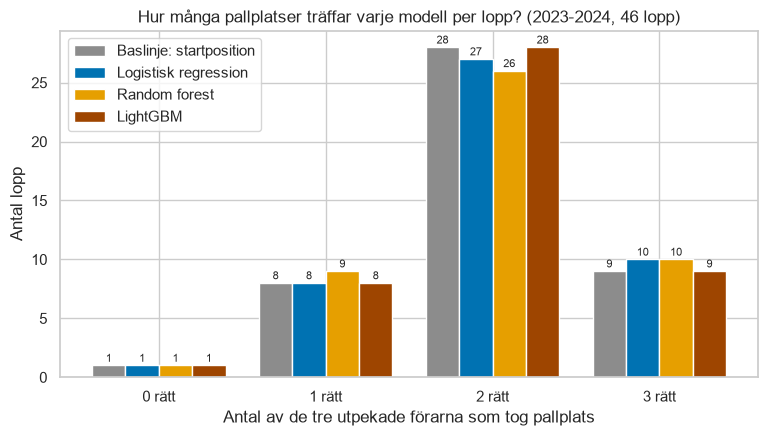

In [46]:
def hits_per_race(data, score):
    """Antal av de tre högst rankade förarna i varje lopp som tog pallplats (0-3)."""
    tmp = data[["raceId", "podium"]].copy()
    tmp["score"] = np.asarray(score)
    tmp["rank"] = tmp.groupby("raceId")["score"].rank(method="first", ascending=False)
    return tmp[tmp["rank"] <= 3].groupby("raceId")["podium"].sum()

# Antal lopp med 0, 1, 2 och 3 rätt för varje modell
counts = pd.DataFrame({
    name: hits_per_race(valid, score).value_counts().reindex([0, 1, 2, 3], fill_value=0)
    for name, score in valid_scores.items()
})

fig, ax = plt.subplots(figsize=(9, 4.5))
width = 0.2
x = np.arange(4)
for k, (name, color) in enumerate(colors.items()):
    bars = ax.bar(x + (k - 1.5) * width, counts[name], width, label=name, color=color)
    ax.bar_label(bars, fontsize=8, padding=1)
ax.set_xticks(x)
ax.set_xticklabels(["0 rätt", "1 rätt", "2 rätt", "3 rätt"])
ax.set_xlabel("Antal av de tre utpekade förarna som tog pallplats")
ax.set_ylabel("Antal lopp")
ax.set_title("Hur många pallplatser träffar varje modell per lopp? (2023-2024, 46 lopp)")
ax.legend()
plt.show()

**Tolkning:** Alla modeller och baslinjen ger nästan exakt samma fördelning. I 26-28 av de 46 loppen träffar de två av de tre pallplatserna, i 9-10 lopp träffar de alla tre, och i 8-9 lopp bara en. Bara i ett enda lopp träffas ingen av dem. Skillnaden mellan den bästa och sämsta modellen är högst ett par lopp, vilket stämmer med att prestandaskillnaderna i 6.7 var små. Maskininlärningsmodellerna pekar alltså ut nästan samma förare som den enkla regeln att de som startar längst fram hamnar på pallen. Den sällsynta tredje pallplatsen, som ofta tas av någon som startat längre bak, är det som är svårast att förutse.

##### Stämmer modellernas sannolikheter med verkligheten?

Modellerna ger varje förare en sannolikhet för pallplats. Om en modell säger "30 %" bör ungefär 30 av 100 sådana förare faktiskt ta pallplats. Det kallas att sannolikheterna är **kalibrerade**. Jag delar in förarna i sex grupper efter modellens sannolikhet (från lägst till högst) och jämför gruppens genomsnittliga förutsägelse (x-axeln) med den faktiska andelen pallplatser (y-axeln). Ju närmare den streckade diagonalen en linje ligger, desto bättre stämmer modellen med verkligheten.

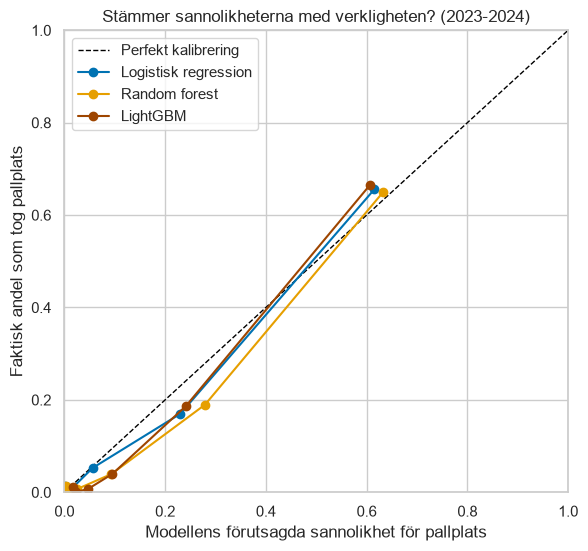

In [47]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], linestyle="--", color="black", linewidth=1, label="Perfekt kalibrering")

for name in ["Logistisk regression", "Random forest", "LightGBM"]:
    observed, predicted = calibration_curve(y_valid, valid_scores[name], n_bins=6, strategy="quantile")
    ax.plot(predicted, observed, marker="o", color=colors[name], label=name)

ax.set_xlabel("Modellens förutsagda sannolikhet för pallplats")
ax.set_ylabel("Faktisk andel som tog pallplats")
ax.set_title("Stämmer sannolikheterna med verkligheten? (2023-2024)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()
plt.show()

**Tolkning:** Alla tre modellers kurvor ligger nära diagonalen, så sannolikheterna är i stort sett pålitliga. För de förare som modellerna ger högst sannolikhet (omkring 62 %) tog 65-66 % faktiskt pallplats. För förare i mitten av skalan är modellerna något för optimistiska: random forest förutsäger i genomsnitt 28 % men utfallet blev 19 %, och logistisk regression 23 % mot 17 %. Logistisk regression ligger i stort sett närmast diagonalen. Eftersom valideringsdelen bara innehåller 138 pallplatser fördelade på sex grupper är kurvorna ändå osäkra, så små avvikelser ska inte tolkas för hårt. Den goda kalibreringen betyder att modellens sannolikheter går att visa för en användare i appen, och att det troligen finns lite att vinna på en särskild kalibrering av dem.

### 6.8 Val av slutmodell

| | Logistisk regression | Random forest | LightGBM |
|---|---|---|---|
| PR-AUC (snitt över perioder) | 0,715 | 0,717 | 0,707 |
| ROC-AUC (snitt över perioder) | 0,931 | 0,938 | 0,936 |
| Tolkbarhet | Hög: en vikt per feature | Medel: feature importance och SHAP | Medel: feature importance och SHAP |
| Risk för överanpassning | Låg | Medel | Hög, kräver försiktig trimning |
| Antal inställningar att trimma | 1 | 2 | 3 |
| Kan fånga samspel mellan features | Nej | Ja | Ja |

**Val:** Jag väljer **logistisk regression** som slutmodell.

**Motivering:** Prestandaskillnaderna mellan modellerna är försumbara jämfört med variationen mellan perioderna (se 6.7), så ingen modell är påvisbart bäst. När resultaten är jämna väljer jag den **enklaste** modellen. Den är lätt att förklara (varje feature har en vikt), ger minst överanpassning, har bara en inställning att trimma och ger sannolikheter som är enkla att presentera i appen.

**Vad uppoffrar jag?** Random forest hade 0,007 högre genomsnittlig ROC-AUC. Logistisk regression kan inte fånga samspel mellan features (till exempel att startposition betyder olika mycket på olika banor) och är mindre flexibel. Eftersom ingen vinst syns i datan för de mer flexibla modellerna är det en liten uppoffring. Random forest och LightGBM använder jag fortfarande i kapitel 7 för att tolka vilka features som väger tyngst, och som jämförelse.

### 6.9 Slutlig utvärdering på testdelen

Nu används testdelen (2025-2026) för första och enda gången. Modellerna är de bästa från sökningen i 6.7, **tränade om på all utvecklingsdata (2014-2024)**. Min slutmodell är logistisk regression, vilket jag bestämde i 6.8 innan jag tittade på testet. De andra två modellerna redovisas bara som jämförelse. **Jag ändrar inget i modellerna eller i valet efter att ha sett testresultatet**, eftersom testet då inte längre vore ett ärligt test.

In [48]:
# Slutmodellerna: bästa inställningarna, tränade på all utvecklingsdata (2014-2024)
final_models = {name: search.best_estimator_ for name, search in searches.items()}

# Poäng för varje förare i testdelen (baslinjens poäng är minus startposition)
test_scores = {"Baslinje: startposition": -test["grid_adj"].values}
for name, model in final_models.items():
    test_scores[name] = model.predict_proba(X_test)[:, 1]

final_results = pd.DataFrame(
    [evaluate(name, test, y_test, score) for name, score in test_scores.items()]
).set_index("model")
final_results.round(3)

,roc_auc,pr_auc,top3_hit_rate,all_three_correct
model,,,,
Baslinje: startposition,0.930,0.696,0.692,0.282
Logistisk regression,0.939,0.739,0.692,0.256
Random forest,0.946,0.753,0.684,0.256
LightGBM,0.946,0.748,0.709,0.282


#### Hur säkra är skillnaderna? (bootstrap över lopp)

Testdelen har bara 39 lopp, så resultaten är osäkra. Skillnaden mellan två modeller kan bero på vilka lopp som råkade hamna i testdelen. För att uppskatta osäkerheten använder jag **bootstrap**: jag drar 1 000 gånger slumpmässigt 39 lopp *med återläggning* ur testdelen (så att samma lopp kan komma med flera gånger och andra utelämnas), räknar om alla mått varje gång och ser hur mycket de varierar. Mellan det 2,5:e och 97,5:e percentilen får jag ett **95 %-igt konfidensintervall**. Jag räknar också ut skillnaden mellan varje modell och baslinjen. Om intervallet för skillnaden **innehåller 0** kan jag inte med säkerhet säga att modellen är bättre än baslinjen.

In [49]:
rng = np.random.default_rng(42)          # fast slumptal så att resultatet blir detsamma varje gång
test_r = test.reset_index(drop=True)
y_arr = test_r["podium"].values
race_rows = test_r.groupby("raceId").indices      # vilka rader som hör till varje lopp
race_ids = np.array(list(race_rows))
race_hits = {name: hits_per_race(test_r, score) for name, score in test_scores.items()}

N_BOOT = 1000
metrics = ["roc_auc", "pr_auc", "top3_hit_rate"]
boot = {name: {m: [] for m in metrics} for name in test_scores}

for _ in range(N_BOOT):
    # Dra 39 lopp med återläggning och samla deras rader
    sampled = rng.choice(race_ids, size=len(race_ids), replace=True)
    idx = np.concatenate([race_rows[r] for r in sampled])
    for name, score in test_scores.items():
        boot[name]["roc_auc"].append(roc_auc_score(y_arr[idx], score[idx]))
        boot[name]["pr_auc"].append(average_precision_score(y_arr[idx], score[idx]))
        boot[name]["top3_hit_rate"].append(race_hits[name].loc[sampled].mean() / 3)

# Sammanfatta: värde, konfidensintervall och skillnad mot baslinjen
baseline = "Baslinje: startposition"
rows = []
for name in test_scores:
    for metric in metrics:
        values = np.array(boot[name][metric])
        diff = values - np.array(boot[baseline][metric])    # samma lopp i varje dragning
        rows.append({
            "model": name, "metric": metric,
            "value": final_results.loc[name, metric],
            "ci_low": np.percentile(values, 2.5), "ci_high": np.percentile(values, 97.5),
            "diff_mean": diff.mean(),
            "diff_low": np.percentile(diff, 2.5), "diff_high": np.percentile(diff, 97.5),
            "share_better": (diff > 0).mean(),
        })
boot_df = pd.DataFrame(rows)

In [50]:
summary = boot_df[boot_df["model"] != baseline].copy()
summary["diff"] = summary.apply(
    lambda r: f"{r.diff_mean:+.3f} [{r.diff_low:+.3f}, {r.diff_high:+.3f}]", axis=1)
summary.pivot(index="model", columns="metric", values="diff")[metrics]

metric,roc_auc,pr_auc,top3_hit_rate
model,,,
LightGBM,"+0.017 [-0.004, +0.042]","+0.054 [+0.000, +0.108]","+0.017 [+0.000, +0.043]"
Logistisk regression,"+0.009 [-0.009, +0.029]","+0.043 [-0.036, +0.118]","+0.000 [-0.051, +0.051]"
Random forest,"+0.016 [-0.007, +0.043]","+0.057 [-0.003, +0.115]","-0.009 [-0.043, +0.017]"


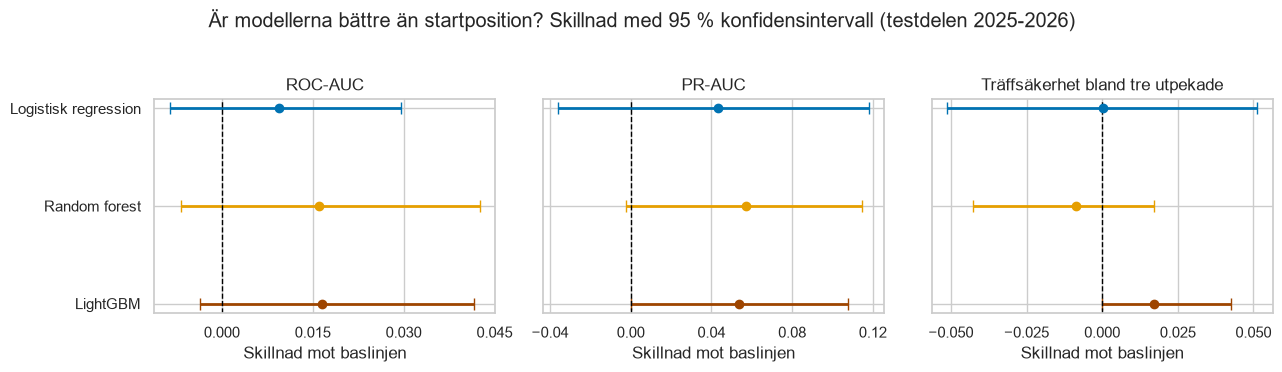

In [51]:
from matplotlib.ticker import MaxNLocator

titles = {"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC", "top3_hit_rate": "Träffsäkerhet bland tre utpekade"}
models_only = [name for name in test_scores if name != baseline][::-1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, metric in zip(axes, titles):
    for y, name in enumerate(models_only):
        r = boot_df[(boot_df["model"] == name) & (boot_df["metric"] == metric)].iloc[0]
        ax.errorbar(r["diff_mean"], y,
                    xerr=[[r["diff_mean"] - r["diff_low"]], [r["diff_high"] - r["diff_mean"]]],
                    fmt="o", color=colors[name], capsize=4, linewidth=2)
    ax.axvline(0, color="black", linestyle="--", linewidth=1)   # 0 = ingen skillnad mot baslinjen
    ax.set_yticks(range(len(models_only)))
    ax.set_yticklabels(models_only)
    ax.xaxis.set_major_locator(MaxNLocator(5))
    ax.set_title(titles[metric])
    ax.set_xlabel("Skillnad mot baslinjen")
fig.suptitle("Är modellerna bättre än startposition? Skillnad med 95 % konfidensintervall (testdelen 2025-2026)", y=1.03)
plt.tight_layout()
plt.show()

**Tolkning:** På testdelen (39 lopp, 2025-2026) får logistisk regression ROC-AUC 0,939 och PR-AUC 0,739, jämfört med 0,930 och 0,696 för baslinjen som bara använder startposition. Alla tre modeller har något högre ROC-AUC och PR-AUC än baslinjen, men **skillnaderna är inte statistiskt säkerställda**: konfidensintervallen för skillnaden innehåller (eller ligger precis vid) 0. I bootstrap-dragningarna var logistisk regression bättre än baslinjen i 84 % (ROC-AUC) och 86 % (PR-AUC) av fallen. För träffsäkerheten bland de tre utpekade förarna per lopp är logistisk regression precis lika bra som baslinjen (0,692 mot 0,692), och bara LightGBM ligger över (0,709, skillnad +0,017 med intervall från 0,000).

Random forest och LightGBM har något högre ROC- och PR-AUC än logistisk regression på testdelen, men skillnaderna mellan modellerna är små jämfört med osäkerheten. Eftersom modellvalet gjordes på korsvalideringen innan testet ändrar jag det inte i efterhand.

Sammanfattningsvis: modellerna ger en **liten men inte säkerställd förbättring** jämfört med att bara titta på startpositionen. Riktningen är densamma som i korsvalideringen (alla tre modeller slog baslinjen i samtliga tre perioder), men med bara 39 testlopp räcker datan inte för att visa en tydlig skillnad. Bakom resultatet ligger att startpositionen redan fångar det mesta av vad som avgör pallplats. Resten beror på sådant som är svårt att förutse före loppet, till exempel olyckor, haverier och strategi. Observera också att 2026 är en ofullständig säsong (15 lopp) och att kvaltiderna för Miami 2025 saknas i datan.

## 7. Tolkning av modellen

Att en modell har bra siffror räcker inte, jag vill också förstå *varför* den gissar som den gör. Jag tittar på det på tre sätt:

1. **Modellens vikter** (logistisk regression): vilka features trycker sannolikheten för pallplats uppåt respektive nedåt?
2. **Permutation importance**: hur mycket sämre blir modellen om jag slumpar om en feature? Fungerar för alla tre modellerna.
3. **Ablationsanalys**: hur mycket bättre blir modellen när jag lägger till grupp efter grupp av features?

### 7.1 Vikter i den logistiska regressionen

Logistisk regression ger varje feature en **koefficient** (en vikt). Eftersom alla features skalades (`StandardScaler`) innan modellen tränades är koefficienterna jämförbara. De anger hur mycket modellens "poäng" ändras när featuren ökar med **en standardavvikelse**.

- **Negativ koefficient**: högre värde på featuren gör pallplats *mindre* sannolik.
- **Positiv koefficient**: högre värde gör pallplats *mer* sannolik.

Jag räknar också om koefficienten till en **oddskvot** (`exp(koefficient)`). En oddskvot på 0,5 betyder att oddsen för pallplats halveras när featuren ökar en standardavvikelse. En oddskvot över 1 betyder att oddsen ökar.

Här används den slutliga modellen, tränad på all utvecklingsdata (2014-2024).

In [53]:
import numpy as np

log_reg = final_models["Logistisk regression"]

# Koefficienterna ligger i sista steget i pipelinen
coefs = pd.Series(log_reg.named_steps["logisticregression"].coef_[0], index=features)

coef_table = pd.DataFrame({
    "koefficient": coefs,
    "oddskvot": np.exp(coefs),
}).sort_values("koefficient")

coef_table.round(2)

,koefficient,oddskvot
grid_adj,-1.94,0.14
team_avg_finish_5,-0.42,0.66
driver_avg_finish_5,-0.26,0.77
gap_to_pole_pct,-0.23,0.79
team_podium_rate_5,0.17,1.19
driver_podium_rate_5,0.20,1.22
grid_vs_quali,0.32,1.38


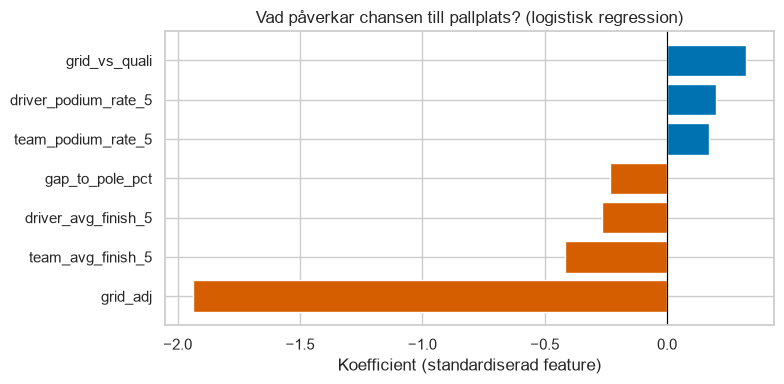

In [54]:
fig, ax = plt.subplots(figsize=(8, 4))

# Blå = ökar chansen till pallplats, orange = minskar den
bar_colors = ["#0072B2" if v > 0 else "#D55E00" for v in coef_table["koefficient"]]
ax.barh(coef_table.index, coef_table["koefficient"], color=bar_colors)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Koefficient (standardiserad feature)")
ax.set_title("Vad påverkar chansen till pallplats? (logistisk regression)")
plt.tight_layout()
plt.show()

**Tolkning**

- **`grid_adj` (startposition) dominerar totalt.** Koefficienten är cirka −1,94, alltså långt större än alla andra. Oddskvoten är 0,14: för varje standardavvikelse (ca 6 platser) längre bak på griden sjunker oddsen för pallplats till ungefär en sjundedel. Det stämmer med intuitionen att den som startar långt fram oftast också slutar långt fram.
- **Stallets och förarens form** (`team_avg_finish_5`, `driver_avg_finish_5`) har negativa koefficienter (−0,42 och −0,26). Ett lågt snitt (bra resultat på sistone) ger alltså högre chans. Även det är logiskt.
- **`gap_to_pole_pct`** är negativ (−0,23): ju långsammare i kvalet jämfört med pole, desto lägre chans.
- **`team_podium_rate_5` och `driver_podium_rate_5`** är positiva (+0,17 och +0,20), alltså fler pallplatser nyligen ger högre chans.
- **`grid_vs_quali` är positiv (+0,32), vilket först ser konstigt ut.** Featuren är *kvalposition minus startposition*. Modellen jämför alltså en förare med andra som startar från samma plats. Om någon startar sämre än han kvalade (t.ex. på grund av en gridstraff) är bilen ofta snabbare än startplatsen antyder, och då är chansen högre.

**Varning:** Koefficienter är svåra att tolka isolerat när features hänger ihop (t.ex. startposition och kvalresultat). Därför kompletterar jag med två andra metoder.

### 7.2 Permutation importance

Koefficienter finns bara för logistisk regression. För att kunna jämföra alla tre modeller använder jag **permutation importance**:

1. Jag mäter modellens PR-AUC på valideringsdatan.
2. Jag slumpar om värdena i *en* feature, så att kopplingen till facit bryts.
3. Jag mäter igen. **Hur mycket modellen försämras** är featurens betydelse.

Metoden upprepas 30 gånger per feature för ett stabilt medelvärde. Jag använder modellerna med de bästa inställningarna, tränade på träningsdatan, och mäter på valideringsdatan (testdatan rör jag inte).

In [55]:
from sklearn.inspection import permutation_importance
from sklearn.base import clone

# Modeller med bästa inställningar från sökningen, tränade på träningsdatan
tuned_models = {}
for name, search in searches.items():
    model = clone(candidates[name][0]).set_params(**search.best_params_)
    model.fit(X_train, y_train)
    tuned_models[name] = model

In [56]:
perm = {}
for name, model in tuned_models.items():
    r = permutation_importance(
        model, X_valid, y_valid,
        scoring="average_precision",   # PR-AUC
        n_repeats=30, random_state=42, n_jobs=-1,
    )
    perm[name] = pd.Series(r.importances_mean, index=features)

perm_df = pd.DataFrame(perm)
perm_df = perm_df.loc[perm_df.mean(axis=1).sort_values().index]   # sortera, viktigast sist
perm_df.round(3)

,Logistisk regression,Random forest,LightGBM
driver_podium_rate_5,0.002,0.002,-0.000
grid_vs_quali,0.006,0.000,0.000
team_avg_finish_5,0.009,0.011,0.002
team_podium_rate_5,0.005,0.011,0.017
driver_avg_finish_5,0.012,0.016,0.006
gap_to_pole_pct,0.025,0.031,0.033
grid_adj,0.358,0.179,0.248


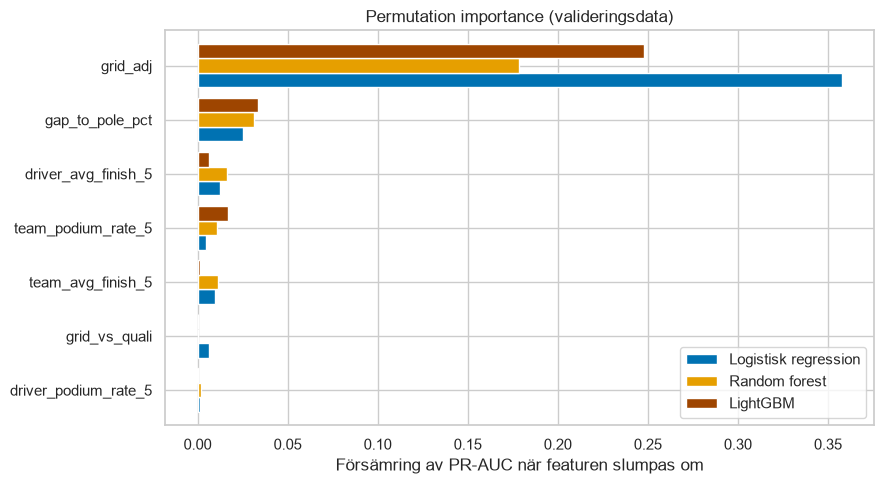

In [57]:
ax = perm_df.plot(kind="barh", figsize=(9, 5), width=0.8,
                  color=[colors[m] for m in perm_df.columns])
ax.set_xlabel("Försämring av PR-AUC när featuren slumpas om")
ax.set_title("Permutation importance (valideringsdata)")
plt.tight_layout()
plt.show()

**Tolkning**

- **Alla tre modeller är överens:** `grid_adj` (startposition) är med stor marginal viktigast. Om den slumpas om faller PR-AUC med 0,36 (logistisk regression), 0,18 (random forest) och 0,25 (LightGBM).
- **På andra plats kommer `gap_to_pole_pct`** (kvaltid jämfört med pole), med en försämring på ca 0,03 för alla modeller. Resten av features ligger på 0,00-0,02, alltså mycket lite.
- Förarens och stallets form betyder något, men klart mindre än startpositionen. Modellerna är inte helt eniga om vilken form-feature som är bäst (random forest och LightGBM rankar t.ex. `team_podium_rate_5` högre än logistisk regression).

**Viktig begränsning:** Features som hänger ihop delar på betydelsen. Om två features innehåller ungefär samma information kan modellen klara sig med den ena när den andra slumpas om, och då ser båda oviktiga ut. Låga värden betyder därför inte att en feature är värdelös, bara att den inte tillför mycket *utöver* de andra. Det undersöker jag i nästa steg.

### 7.3 Ablationsanalys: vad tillför varje grupp av features?

Här bygger jag upp modellen steg för steg och mäter hur resultatet förändras. Jag använder logistisk regression och samma tidsmedvetna korsvalidering som tidigare (PR-AUC och ROC-AUC, medelvärde över de tre valideringsblocken).

1. Bara startposition
2. + kvalresultat (`gap_to_pole_pct`, `grid_vs_quali`)
3. + förarens form
4. + stallets form (alla 7 features)

Därefter gör jag tvärtom: tar bort *en* grupp i taget från den fullständiga modellen och ser vad som händer.

Stegvis uppbygnad:

In [58]:
feature_groups = [
    ("Bara startposition", ["grid_adj"]),
    ("+ kvalresultat", ["grid_adj", "gap_to_pole_pct", "grid_vs_quali"]),
    ("+ förarens form", ["grid_adj", "gap_to_pole_pct", "grid_vs_quali",
                         "driver_avg_finish_5", "driver_podium_rate_5"]),
    ("+ stallets form", features),
]

def cv_scores(cols):
    """Medel-PR-AUC och medel-ROC-AUC över de tidsmedvetna valideringsblocken."""
    pr, roc = [], []
    for tr, va in cv_splits:
        m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          LogisticRegression(max_iter=1000))
        m.fit(X_dev.iloc[tr][cols], y_dev.iloc[tr])
        p = m.predict_proba(X_dev.iloc[va][cols])[:, 1]
        pr.append(average_precision_score(y_dev.iloc[va], p))
        roc.append(roc_auc_score(y_dev.iloc[va], p))
    return np.mean(pr), np.mean(roc)

rows = []
for label, cols in feature_groups:
    pr, roc = cv_scores(cols)
    rows.append({"steg": label, "antal_features": len(cols), "cv_pr_auc": pr, "cv_roc_auc": roc})

ablation = pd.DataFrame(rows).set_index("steg")
ablation.round(3)

,antal_features,cv_pr_auc,cv_roc_auc
steg,,,
Bara startposition,1,0.664,0.916
+ kvalresultat,3,0.684,0.920
+ förarens form,5,0.707,0.928
+ stallets form,7,0.715,0.931


Tar bort en grupp i taget:

In [59]:
groups = {
    "startposition": ["grid_adj"],
    "kval": ["gap_to_pole_pct", "grid_vs_quali"],
    "förarens form": ["driver_avg_finish_5", "driver_podium_rate_5"],
    "stallets form": ["team_avg_finish_5", "team_podium_rate_5"],
}

full_pr, full_roc = cv_scores(features)
rows = [{"modell": "Alla 7 features", "cv_pr_auc": full_pr, "cv_roc_auc": full_roc}]
for g, cols in groups.items():
    rest = [f for f in features if f not in cols]
    pr, roc = cv_scores(rest)
    rows.append({"modell": f"Utan {g}", "cv_pr_auc": pr, "cv_roc_auc": roc})

pd.DataFrame(rows).set_index("modell").round(3)

,cv_pr_auc,cv_roc_auc
modell,,
Alla 7 features,0.715,0.931
Utan startposition,0.678,0.923
Utan kval,0.711,0.930
Utan förarens form,0.715,0.931
Utan stallets form,0.707,0.928


Diagram över stegvis uppbyggnad:

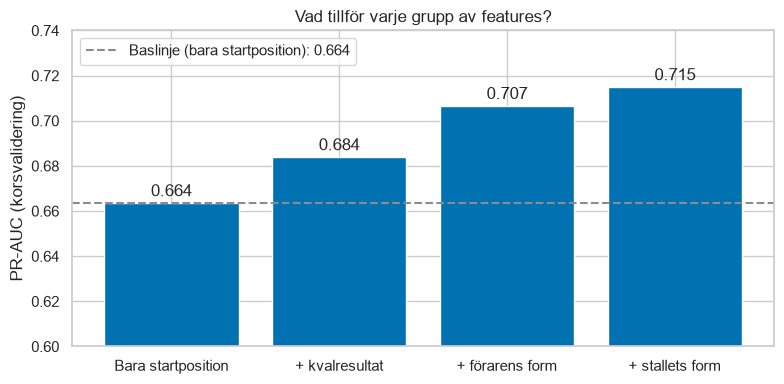

In [60]:
baseline_cv = np.mean([average_precision_score(y_dev.iloc[va], -dev["grid_adj"].iloc[va])
                       for _, va in cv_splits])

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(ablation.index, ablation["cv_pr_auc"], color=colors["Logistisk regression"])
ax.axhline(baseline_cv, color=colors["Baslinje: startposition"], linestyle="--",
           label=f"Baslinje (bara startposition): {baseline_cv:.3f}")

for i, v in enumerate(ablation["cv_pr_auc"]):
    ax.text(i, v + 0.003, f"{v:.3f}", ha="center")

ax.set_ylim(0.6, 0.74)
ax.set_ylabel("PR-AUC (korsvalidering)")
ax.set_title("Vad tillför varje grupp av features?")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Tolkning**    

Observera att Y-axeln börjar på 0,6 för att kunna tyda skillnaderna lättare

Stegvis uppbyggnad (PR-AUC, korsvalidering):

| Steg | PR-AUC | ROC-AUC |
|---|---|---|
| Bara startposition | 0,664 | 0,916 |
| + kvalresultat | 0,684 | 0,920 |
| + förarens form | 0,707 | 0,928 |
| + stallets form | 0,715 | 0,931 |

- Startposition ensam ger redan 0,664, vilket är hela baslinjen. Allt annat bygger vidare på den.
- Kvalresultat, förarens form och stallets form tillför ungefär +0,02, +0,02 och +0,01. Varje grupp ger alltså en **liten** förbättring, och tillsammans cirka +0,05 PR-AUC.

När jag i stället tar bort en grupp i taget från den fullständiga modellen (0,715):

- **Utan startposition: 0,678.** Modellen tappar bara lite, eftersom kvalresultaten innehåller nästan samma information (den som kvalar bra startar för det mesta bra). Det är samma sak som varningen i 7.2: features som hänger ihop kan ersätta varandra.
- **Utan stallets form: 0,707.** Det är den grupp som gör störst skillnad när den tas bort.
- **Utan förarens form: 0,715**, alltså ingen skillnad. Stallets form fångar mycket av samma information (bra förare sitter oftast i bra bilar).
- **Utan kval: 0,711.** Nästan ingen skillnad.

**Slutsats:** Startpositionen är grunden i modellen. Övriga features ger små tillskott, och framför allt stallets form hjälper. Förbättringarna är små och bygger på bara tre valideringsblock, så jag drar inte för stora slutsatser av enskilda decimaler.

### 7.4 SHAP: hur påverkar varje feature varje enskild gissning?

Permutation importance säger hur viktig en feature är *i genomsnitt*. **SHAP** går ett steg längre: för varje enskild förare och lopp visar den hur mycket varje feature knuffade modellens gissning uppåt eller nedåt, jämfört med ett "normalt" läge.

- Modellen börjar från ett **grundvärde**, vilket motsvarar chansen för en genomsnittlig förare (ca 2 % här, eftersom bara 3 av ca 20 når pallen).
- Varje feature lägger sedan till eller drar ifrån en bit. Summan är modellens slutgiltiga gissning.
- SHAP-värdena anges i **log-odds**, samma skala som koefficienterna i 7.1. Positivt värde = ökar chansen, negativt = minskar den.

Jag använder SHAP på den logistiska regressionen (den slutligt valda modellen) och räknar på valideringsdatan.

In [61]:
import shap

lr_model = tuned_models["Logistisk regression"]
lr = lr_model.named_steps["logisticregression"]

# SHAP behöver data i samma form som modellen faktiskt ser den: efter imputering och skalning
prep = lr_model[:-1]                       # pipelinen utan sista steget (själva modellen)
Xtr_t = pd.DataFrame(prep.transform(X_train), columns=features, index=X_train.index)
Xva_t = pd.DataFrame(prep.transform(X_valid), columns=features, index=X_valid.index)

# Använd hela träningsdatan som referens
masker = shap.maskers.Independent(Xtr_t, max_samples=len(Xtr_t))
explainer = shap.LinearExplainer(lr, masker)
shap_values = explainer(Xva_t)

# Genomsnittlig påverkan (absolutvärde) per feature
mean_abs_shap = pd.Series(np.abs(shap_values.values).mean(axis=0), index=features).sort_values(ascending=False)
mean_abs_shap.round(3)

grid_adj                1.444
gap_to_pole_pct         0.534
driver_avg_finish_5     0.301
team_avg_finish_5       0.248
driver_podium_rate_5    0.129
team_podium_rate_5      0.121
grid_vs_quali           0.081
dtype: float64

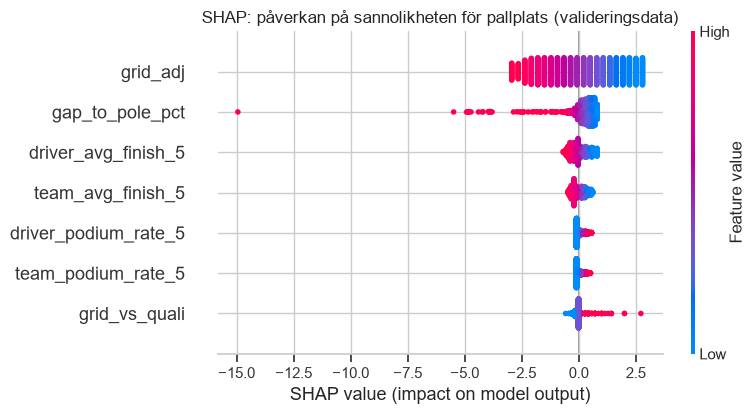

In [62]:
shap.plots.beeswarm(shap_values, show=False)
plt.title("SHAP: påverkan på sannolikheten för pallplats (valideringsdata)")
plt.tight_layout()
plt.show()

**Så läser du diagrammet:** Varje punkt är en förare i ett lopp. Features står på raderna, sorterade efter betydelse. Punktens plats på x-axeln visar hur mycket featuren påverkade just den gissningen (höger = ökade chansen, vänster = minskade den). Färgen visar featurens värde (rött = högt, blått = lågt).

**Tolkning**

- **`grid_adj` är i en klass för sig** (genomsnittlig påverkan 1,44, nästa feature 0,53). Blå punkter (låg siffra = start långt fram) ligger långt åt höger, alltså ökad chans. Röda punkter (start långt bak) ligger åt vänster. Det är precis vad man väntar sig.
- **`gap_to_pole_pct`** kommer tvåa (0,53). Små avstånd till pole ger högre chans.
- **Förarens och stallets form** (`driver_avg_finish_5` 0,30 och `team_avg_finish_5` 0,25) har måttlig betydelse. Podium-andelarna och `grid_vs_quali` ligger på 0,08-0,13, alltså bara en liten del av vad startpositionen gör.
- Rangordningen stämmer med permutation importance (7.2) och ablationen (7.3). Tre olika metoder pekar åt samma håll, vilket gör slutsatsen mer trovärdig.

### 7.5 Två exempel: varför gissade modellen som den gjorde?

Ett **waterfall-diagram** visar hur en enskild gissning byggs upp: från grundvärdet, via varje features bidrag, till slutresultatet. Jag väljer två lopp där modellen hade helt olika förutsättningar:

1. **Max Verstappen, Australiens GP 2024.** Startade från pole och modellen var mycket säker. Men han bröt loppet (ingen pallplats).
2. **Pierre Gasly, Nederländernas GP 2023.** Startade 12:a och modellen gav nästan ingen chans. Han tog ändå pallplats.

Poängen är att visa att modellen resonerar rimligt även när den har fel. Fel i dessa fall beror på sådant som inte går att veta före start (haveri, safety car, regn).

Max Verstappen, Australian Grand Prix 2024: modellens chans 89.6%, verkligt utfall: ingen pallplats


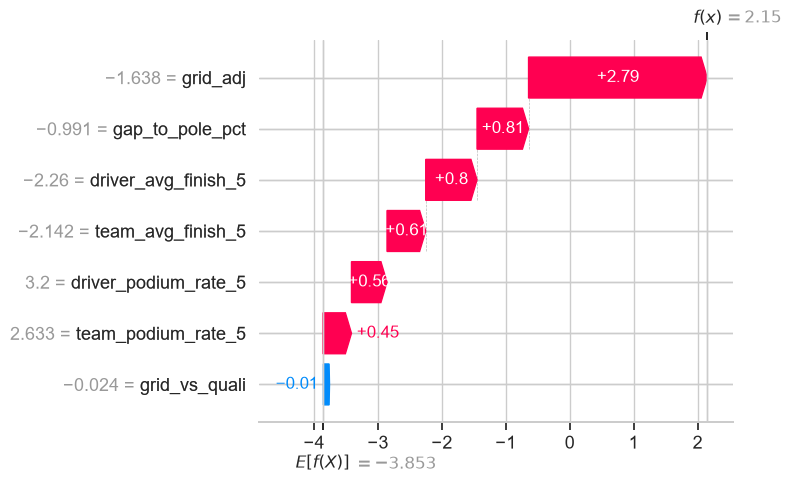

In [64]:
def forklaring(lopp, ar, forare):
    """Waterfall-diagram för en förare i ett lopp i valideringsdatan."""
    rad = valid[(valid["race_name"] == lopp) & (valid["year"] == ar) & (valid["driver"] == forare)]
    idx = rad.index[0]
    pos = X_valid.index.get_loc(idx)
    sannolikhet = lr_model.predict_proba(X_valid)[pos, 1]
    utfall = "pallplats" if rad["podium"].iloc[0] == 1 else "ingen pallplats"
    print(f"{forare}, {lopp} {ar}: modellens chans {sannolikhet:.1%}, verkligt utfall: {utfall}")
    shap.plots.waterfall(shap_values[pos], show=False)
    plt.tight_layout()
    plt.show()

forklaring("Australian Grand Prix", 2024, "Max Verstappen")

Pierre Gasly, Dutch Grand Prix 2023: modellens chans 0.0%, verkligt utfall: pallplats


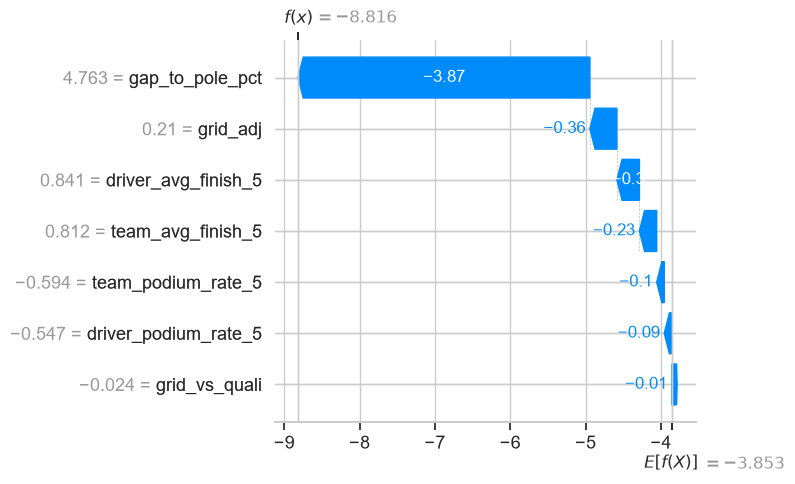

In [65]:
forklaring("Dutch Grand Prix", 2023, "Pierre Gasly")

**Tolkning**

- **Verstappen (pole):** Modellen gav honom ca 90 % chans. Nästan hela uppgången kommer från `grid_adj` (start från plats 1), och förarens och stallets formsiffror trycker i samma riktning. Han bröt loppet, så utfallet blev "ingen pallplats". Det är inget modellfel i vanlig mening: sannolikheten var hög men aldrig 100 %.
- **Gasly (start 12:a):** Modellen gav honom ca 0,01 %. Startpositionen drar ned gissningen kraftigt (ca −3,9 i log-odds) och inget annat väger upp det. Gasly tog ändå pallplats i ett lopp där mycket hände under loppet. Modellen ser bara det som är känt före start.
- Båda exemplen visar modellens styrka (tydliga och logiska resonemang) och dess gräns (den kan inte förutse händelser under loppet).

### 7.6 Sammanfattning: vad har vi lärt oss om modellen?

Tre helt olika metoder (vikter, permutation importance, SHAP) och ablationsanalysen ger samma bild:

1. **Startposition är den överlägset viktigaste faktorn.** Det är den enda feature som modellen verkligen behöver. Resten är finjustering.
2. **Kvaltid (avstånd till pole)** kommer tvåa och tillför lite utöver startpositionen.
3. **Förarens och stallets form** tillför små men konsekventa förbättringar. Stallets form är något mer användbar än förarens.
4. **Modellens resonemang är logiskt och går att förklara** för varje enskild gissning, vilket är en fördel med den enkla logistiska regressionen.
5. **Det modellen inte kan se:** händelser under loppet som haverier, safety car, väder och strategi. Det sätter en övre gräns för hur bra en modell som bara använder förhandsinformation kan bli.